# WGCNA - oyster age
Taking the output from DESeq to look at gene networks and correlations with different factors

## 0. load libraries

In [4]:
library(tidyverse)
library(WGCNA)

## 1. read and format CSVs

## 3. WGCNA

In [121]:
# important setting, cannot omit
options(stringsAsFactors = FALSE)

In [122]:
# allow multi-threading within WGCNA
enableWGCNAThreads()

Allowing parallel execution with up to 55 working processes.


### 1. structure WGCNA input

**Expected input**:
- Rows = samples
- Columns = genes (or probes/features)
- Values = numeric expression values

#### A. format vst normalized counts matrix

In [9]:
# counts matrix - sample x gene name
dataExpr <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/vst_allSamples.csv') %>%
  t() %>%
  as.data.frame() %>%
  row_to_names(row_number = 1, remove_row = TRUE)


# Convert all expression values to numeric
dataExpr <- dataExpr %>%
  mutate(across(everything(), as.numeric))

dim(dataExpr)
head(dataExpr)

[1]   114 26299

,LOC144621260,LOC144621269,LOC111120925,LOC144621283,LOC144621276,LOC111115920,LOC144621308,LOC111112629,LOC111102827,LOC111102829,⋯,LOC111110910,LOC111110817,LOC111111216,LOC111111215,LOC111111213,LOC111114497,LOC111114498,LOC111112304,LOC144621306,LOC144621888
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
B1_B1_O01,11.66695,9.122483,9.189670,10.22170,13.50324,9.512109,9.141243,9.618407,10.87359,9.889120,⋯,10.305581,9.925308,9.440448,9.871433,13.57637,9.325028,11.64953,10.91240,8.794755,8.735172
B1_Nu_O03,11.26966,9.978336,8.710781,10.35384,13.27233,9.712293,8.986853,9.760261,10.97684,9.816409,⋯,10.458941,9.419664,9.839531,9.478724,13.54243,9.467267,11.67775,10.65656,8.591124,9.246491
B1_W5_O50,11.45313,11.198837,8.943717,10.59104,13.52601,9.564160,8.812020,10.047886,10.25936,9.922272,⋯,11.091223,9.248750,9.696171,9.594694,13.32123,9.385081,11.80212,10.87398,8.979950,8.785978
B2_B5_O51,11.44434,11.600233,10.081693,10.61658,13.70291,9.481098,9.153930,9.546623,11.33543,10.001400,⋯,11.212399,10.440866,9.576324,9.683796,13.75119,9.564075,11.88102,10.64164,8.591124,8.904048
B2_C4_O40,11.34595,10.642966,8.823398,10.48527,13.58163,9.359553,8.904047,10.364994,10.36717,9.873188,⋯,10.421410,9.152806,9.598530,9.488026,13.37541,9.451180,11.45840,10.88577,8.871120,8.904047
B2_Nu_O12,11.89074,13.983392,8.864449,10.55523,13.53813,9.612035,8.943635,10.126716,11.16500,9.850764,⋯,9.504089,9.332586,10.010147,10.101586,13.75617,9.919905,11.97661,10.90341,9.181830,8.893196


In [10]:
meta_subset <- meta %>% filter(Phase1_treatment == 'control' | is.na(Phase2_treatment))
dim(meta_subset)
head(meta_subset)

[1] 48  9

,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,complete_trtmt
,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<chr>
B1_Nu_O03,both,warm,hypoxic,1,NA,NA,NA,NA,both_NA
B2_Nu_O12,both,warm,hypoxic,2,NA,NA,NA,NA,both_NA
B3_Nu_O24,both,warm,hypoxic,3,NA,NA,NA,NA,both_NA
B4_Nu_O32,both,warm,hypoxic,4,NA,NA,NA,NA,both_NA
B5_Nu_O36,both,warm,hypoxic,5,NA,NA,NA,NA,both_NA
B6_Nu_O47,both,warm,hypoxic,6,NA,NA,NA,NA,both_NA


In [11]:
dataExpr_subset <- dataExpr[rownames(dataExpr) %in% rownames(meta_subset), ]
dim(dataExpr_subset)
head(dataExpr_subset)

[1]    45 26299

,LOC144621260,LOC144621269,LOC111120925,LOC144621283,LOC144621276,LOC111115920,LOC144621308,LOC111112629,LOC111102827,LOC111102829,⋯,LOC111110910,LOC111110817,LOC111111216,LOC111111215,LOC111111213,LOC111114497,LOC111114498,LOC111112304,LOC144621306,LOC144621888
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
B1_Nu_O03,11.26966,9.978336,8.710781,10.35384,13.27233,9.712293,8.986853,9.760261,10.97684,9.816409,⋯,10.458941,9.419664,9.839531,9.478724,13.54243,9.467267,11.67775,10.65656,8.591124,9.246491
B2_Nu_O12,11.89074,13.983392,8.864449,10.55523,13.53813,9.612035,8.943635,10.126716,11.16500,9.850764,⋯,9.504089,9.332586,10.010147,10.101586,13.75617,9.919905,11.97661,10.90341,9.181830,8.893196
B4_Nu_O32,11.27504,13.001485,8.898154,10.59159,13.84378,9.541191,9.228987,10.828706,10.97897,10.282353,⋯,10.506564,9.925116,9.282442,9.906659,13.17866,9.244737,12.18715,11.01696,8.723452,8.674833
B5_Nu_O36,11.28130,8.890075,8.683532,10.30746,12.83481,9.766904,8.976611,10.001465,11.35095,9.549344,⋯,9.931788,9.996263,9.628482,9.766904,13.05975,9.086403,12.15435,11.41640,8.721786,8.751124
B6_Nu_O47,11.41881,9.186827,8.773983,10.60960,12.77543,9.977909,9.023482,9.989540,10.83438,10.072438,⋯,10.348694,10.411004,9.827278,9.776426,12.95822,8.993827,11.83188,11.34869,8.682599,9.077247
C_W5_W52,11.63020,8.857736,9.636097,10.96763,13.68054,9.616625,8.960366,9.807111,10.19713,9.797018,⋯,9.723280,9.895499,9.880667,9.776516,13.56846,9.589127,11.53203,10.89661,8.756614,8.847305


why only 45 and not 48 samples?

In [12]:
meta_subset[!rownames(meta_subset) %in% rownames(dataExpr),]

,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,complete_trtmt
,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<chr>
B3_Nu_O24,both,warm,hypoxic,3,NA,NA,NA,NA,both_NA
C1_C4_W37,control,ambient,normoxic,1,control,ambient,normoxic,4,control_control
H6_Nu_B45,hypoxic,ambient,hypoxic,6,NA,NA,NA,NA,hypoxic_NA


hm okay yea some of these were removed during the filtering steps

#### B. identify and remove genes with missing data 
genes with too many NAs or zero-counts

In [13]:
gsg <- goodSamplesGenes(dataExpr_subset, verbose = 3)
gsg$allOK

dataExpr <- dataExpr[gsg$goodSamples, gsg$goodGenes]
dim(dataExpr_subset) # 45 samples x 26299 genes

 Flagging genes and samples with too many missing values...
  ..step 1


[1] TRUE

[1]    45 26299

#### C. Sample size and gene filtering

removing low-variance genes first:

In [14]:
dataExpr <- dataExpr_subset[, apply(dataExpr_subset, 2, stats::var) > quantile(apply(dataExpr_subset, 2, stats::var), 0.25)]
dim(dataExpr) # 45 samples x 19724 genes

[1]    45 19724

#### D. Sample outlier detection

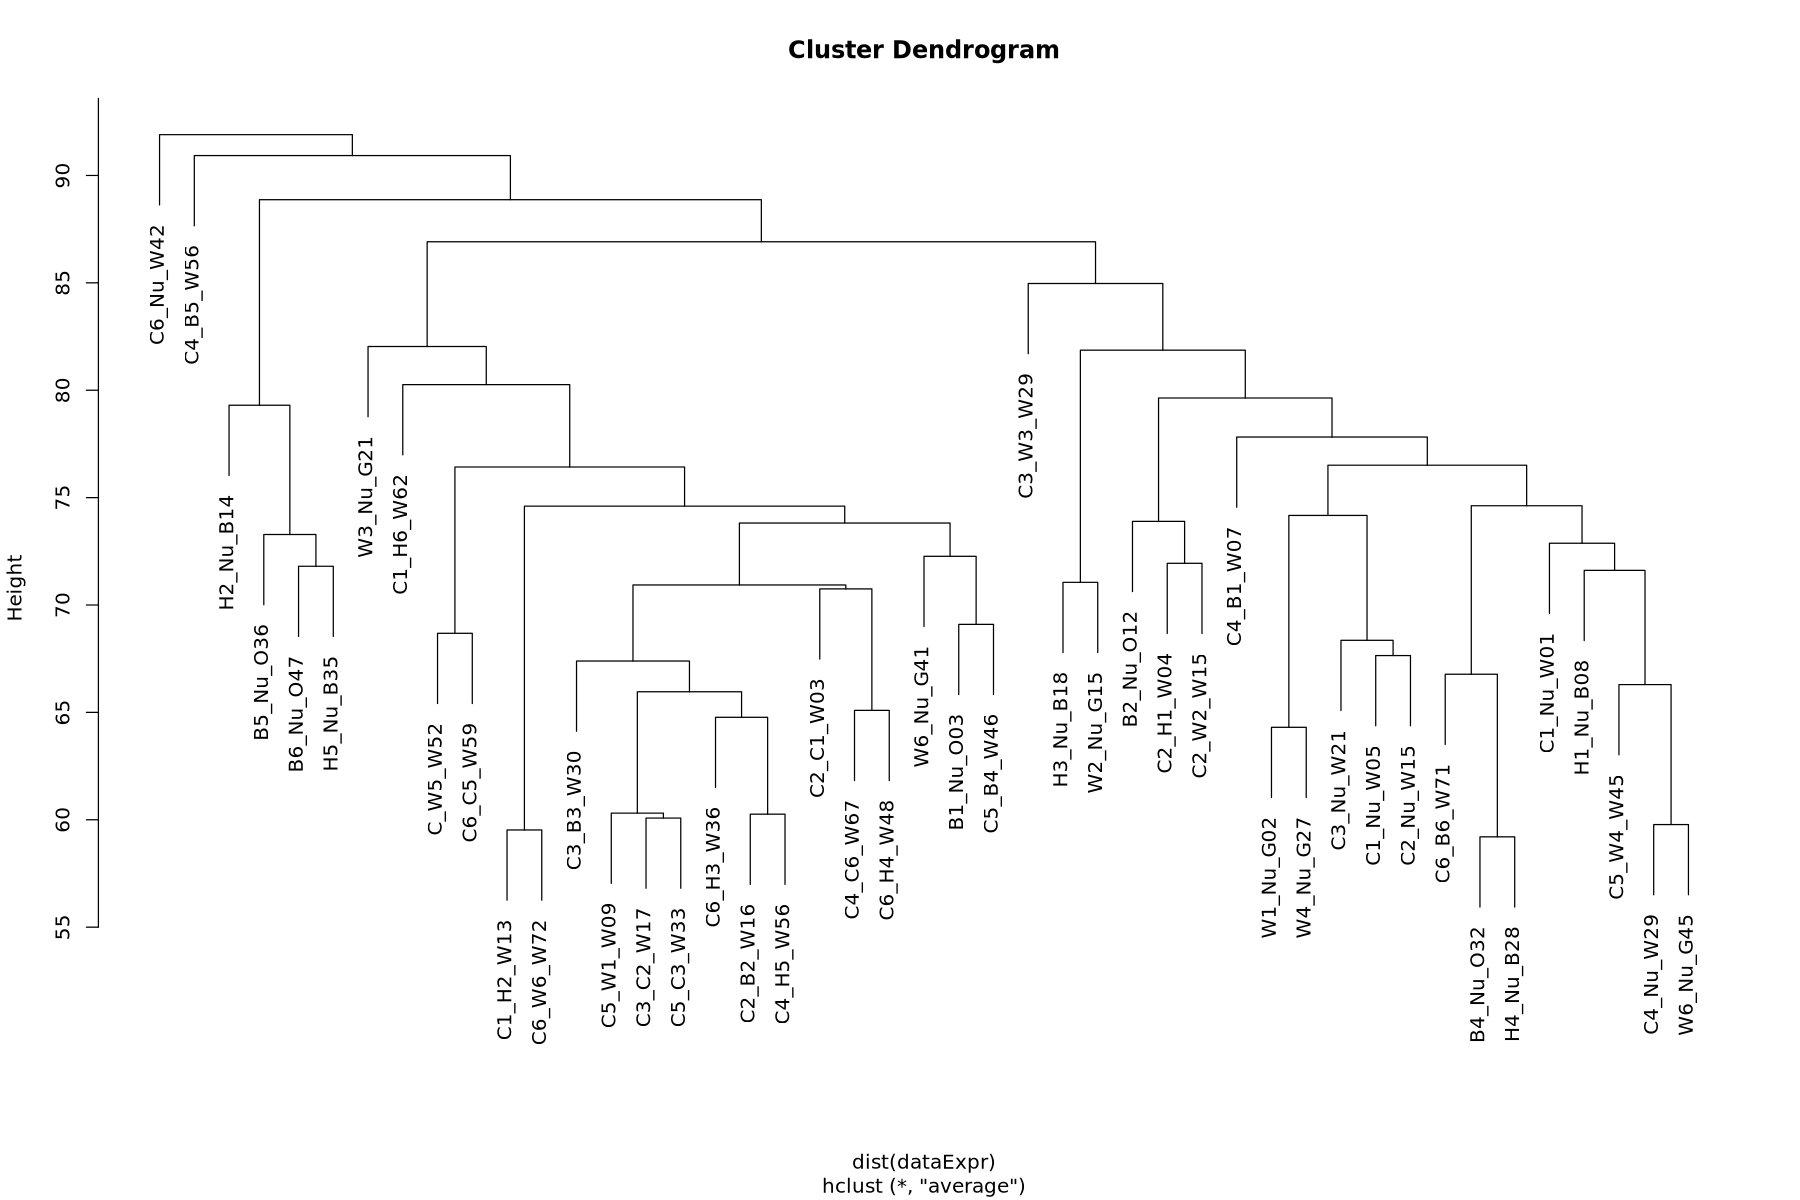

In [15]:
options(repr.plot.width = 15, repr.plot.height = 10)

sampleTree <- hclust(dist(dataExpr), method = "average")
plot(sampleTree)

no obvious outliers to remove

In [16]:
# QC check again
gsg <- goodSamplesGenes(dataExpr, verbose = 3)
if (!gsg$allOK) {
  dataExpr <- dataExpr[gsg$goodSamples, gsg$goodGenes]
}

gsg$allOK

 Flagging genes and samples with too many missing values...
  ..step 1


[1] TRUE

#### E. meta data
could add phenotypic data to this ...

In [17]:
meta <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/sample_metaData.csv') 

# setting samples as rownames and deleting col from df
rownames(meta) <- meta$Sample
meta <- meta[, !colnames(meta) %in% "Sample"]

# removing same samples as dataExpr
meta <- meta[rownames(meta) %in% rownames(dataExpr), ]

meta <- meta %>%
# most recent exposure
mutate(recent_expo = case_when(
    is.na(Phase2_treatment) ~ Phase1_treatment,
    TRUE ~ Phase2_treatment)) %>%
# most recent temperature
mutate(recent_temp = case_when(
    is.na(Phase2_temp) ~ Phase1_temp,
    TRUE ~ Phase2_temp)) %>%
# most recent DO
mutate(recent_DO = case_when(
    is.na(Phase2_DO) ~ Phase1_DO,
    TRUE ~ Phase2_DO))

head(meta)
dim(meta) # 45 samples

,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,recent_expo,recent_temp,recent_DO
,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>
B1_Nu_O03,both,warm,hypoxic,1,NA,NA,NA,NA,both,warm,hypoxic
B2_Nu_O12,both,warm,hypoxic,2,NA,NA,NA,NA,both,warm,hypoxic
B4_Nu_O32,both,warm,hypoxic,4,NA,NA,NA,NA,both,warm,hypoxic
B5_Nu_O36,both,warm,hypoxic,5,NA,NA,NA,NA,both,warm,hypoxic
B6_Nu_O47,both,warm,hypoxic,6,NA,NA,NA,NA,both,warm,hypoxic
C_W5_W52,control,ambient,normoxic,NA,warm,warm,normoxic,5,warm,warm,normoxic


[1] 45 11

In [18]:
# double checking the samples in rownames are the same
all(rownames(meta) == rownames(dataExpr))

[1] TRUE

### 2. simple WGCNA network construction and module identification
start with simple, can progress to consensus if deemed necessary

In [19]:
# final QC check
gsg <- goodSamplesGenes(dataExpr, verbose = 3)
if (!gsg$allOK) {
  dataExpr <- dataExpr[gsg$goodSamples, gsg$goodGenes]
}

gsg$allOK

 Flagging genes and samples with too many missing values...
  ..step 1


[1] TRUE

#### A. choose soft thresholding power (β)
analysis of network topology

In [20]:
powers <- c(1:20)
sft <- pickSoftThreshold(
  dataExpr,
  powerVector = powers,
  networkType = "signed",
  verbose = 5
)


pickSoftThreshold: will use block size 2268.
 pickSoftThreshold: calculating connectivity for given powers...
   ..working on genes 1 through 2268 of 19724


Warning message:
“executing %dopar% sequentially: no parallel backend registered”


   ..working on genes 2269 through 4536 of 19724
   ..working on genes 4537 through 6804 of 19724
   ..working on genes 6805 through 9072 of 19724
   ..working on genes 9073 through 11340 of 19724
   ..working on genes 11341 through 13608 of 19724
   ..working on genes 13609 through 15876 of 19724
   ..working on genes 15877 through 18144 of 19724
   ..working on genes 18145 through 19724 of 19724
   Power SFT.R.sq slope truncated.R.sq mean.k. median.k. max.k.
1      1  0.21500 18.60          0.953  9950.0   9960.00  10500
2      2  0.00557 -1.36          0.859  5240.0   5200.00   6140
3      3  0.27500 -5.10          0.798  2870.0   2810.00   3890
4      4  0.59000 -5.13          0.864  1640.0   1570.00   2630
5      5  0.78600 -4.51          0.928   965.0    904.00   1880
6      6  0.85900 -3.80          0.952   591.0    535.00   1390
7      7  0.89300 -3.27          0.961   374.0    324.00   1080
8      8  0.90000 -2.94          0.958   245.0    201.00    862
9      9  0.89200 -2.68

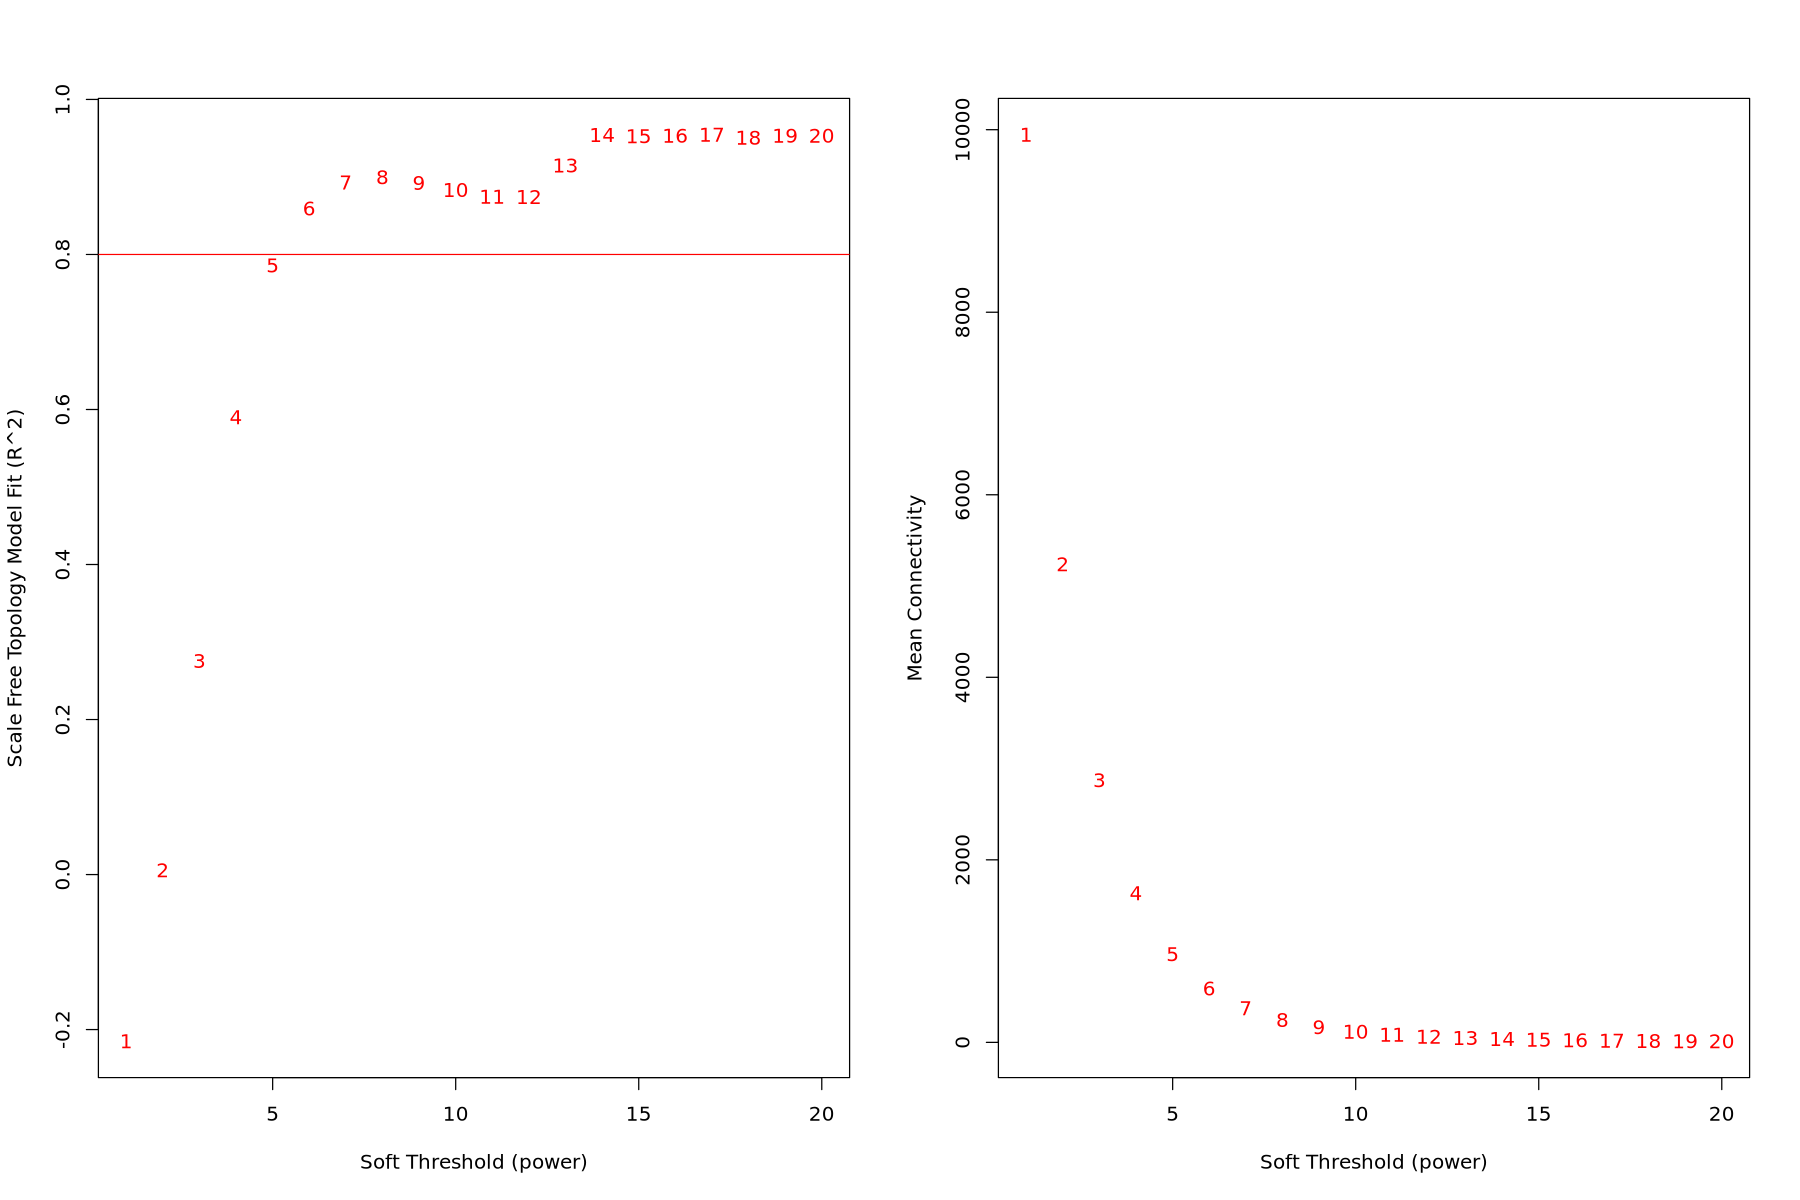

In [21]:
par(mfrow = c(1,2))
plot(
  sft$fitIndices[,1],
  -sign(sft$fitIndices[,3]) * sft$fitIndices[,2],
  xlab = "Soft Threshold (power)",
  ylab = "Scale Free Topology Model Fit (R^2)",
  type = "n"
)
text(
  sft$fitIndices[,1],
  -sign(sft$fitIndices[,3]) * sft$fitIndices[,2],
  labels = powers,
  col = "red"
)
abline(h = 0.8, col = "red")

plot(
  sft$fitIndices[,1],
  sft$fitIndices[,5],
  xlab = "Soft Threshold (power)",
  ylab = "Mean Connectivity",
  type = "n"
)
text(
  sft$fitIndices[,1],
  sft$fitIndices[,5],
  labels = powers,
  col = "red"
)


**left plot - scale-free topology**

the red line is where R^2 is 0.8 - you want the lowest power that reaches this - 13 is just above 0.8 and anything after 13 plateaus

**right plot - mean connectivity**

connectivity should not collapse to 0 - by power ~14, the connectivity approaches 0

based on this, I think power of 5 should be appropriate

#### B. co-expression similarity and adjacency

creating adjacency matrix

In [22]:
softPower <- 6

calculate co-expression adjacency using soft threshold power of 6

doing signed like the phase 2 vs. phase 2 analysis

In [23]:
# signed
adjacency_sign <- adjacency(dataExpr, power = softPower, type = 'signed') 
head(adjacency_sign)

,LOC144621260,LOC144621269,LOC111120925,LOC144621283,LOC144621276,LOC111115920,LOC144621308,LOC111112629,LOC111102827,LOC111102829,⋯,LOC144621545,LOC111110910,LOC111110817,LOC111111216,LOC111111215,LOC111111213,LOC111114497,LOC111114498,LOC111112304,LOC144621888
LOC144621260,1.000000000,0.151755997,0.085674076,0.016766837,0.037264371,0.006508984,0.004905376,0.01384503,0.0185508211,0.028057858,⋯,0.011490569,0.014254470,0.044961525,0.0179235467,0.088492829,0.029274707,0.012724423,0.011941656,1.083835e-02,0.008090810
LOC144621269,0.151755997,1.000000000,0.027650596,0.008871447,0.022330093,0.004240960,0.061126705,0.02376789,0.1921640330,0.058486629,⋯,0.007028695,0.028240557,0.053942717,0.0167233742,0.137378299,0.016824145,0.005861423,0.028918192,9.973316e-03,0.009846236
LOC111120925,0.085674076,0.027650596,1.000000000,0.022482062,0.027567705,0.004569804,0.010799713,0.02020284,0.0368386934,0.009272681,⋯,0.030546144,0.009052591,0.017017631,0.0009932533,0.002637150,0.051160865,0.007979056,0.039477394,3.861654e-03,0.013726768
LOC144621283,0.016766837,0.008871447,0.022482062,1.000000000,0.319355177,0.010134724,0.008752911,0.02642042,0.0003017700,0.004972198,⋯,0.027753514,0.051195781,0.005557144,0.0209030968,0.018188010,0.049240861,0.164089896,0.001511191,1.423447e-04,0.005217575
LOC144621276,0.037264371,0.022330093,0.027567705,0.319355177,1.000000000,0.002060215,0.007984156,0.04225030,0.0008058106,0.010653293,⋯,0.006782157,0.049421500,0.008040966,0.0033351901,0.021139047,0.182949313,0.355100428,0.014449975,2.449226e-05,0.001942045
LOC111115920,0.006508984,0.004240960,0.004569804,0.010134724,0.002060215,1.000000000,0.027988550,0.03711342,0.0153987205,0.014932196,⋯,0.026690642,0.004585083,0.021364805,0.0621745485,0.009917118,0.004443689,0.014924315,0.009354780,6.357258e-02,0.080284230


In [101]:
write.csv(as.data.frame(rownames(adjacency_sign)), '/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/wgcna_UniversalGeneList.csv', row.names = FALSE)

#### C. Topological Overlap Matrix (TOM)
transform adjacency into TOM to minimize effects of noise and spurious associations - calculate corresponding dissimilarity

In [24]:
## SIGNED
# turn adjacency into topological overlap
TOM_sign <- TOMsimilarity(adjacency_sign)
head(TOM_sign)

# calculate dissimilarity
dissTOM_sign <- 1-TOM_sign
head(dissTOM_sign)

..connectivity..
..matrix multiplication (system BLAS)..
..normalization..
..done.


1.00000000,0.15407552,0.05408841,0.03722154,0.04858712,0.02717676,0.03402673,0.03302548,0.04814895,0.04330642,⋯,0.02686934,0.03240101,0.04265896,0.03180224,0.05805458,0.03036108,0.03987651,0.02758214,0.026405085,0.02712698
0.15407552,1.00000000,0.05325637,0.02340466,0.03344629,0.03142652,0.09069408,0.06109168,0.13629177,0.10733517,⋯,0.03380913,0.05018560,0.08475460,0.04087204,0.13943827,0.03609685,0.02040688,0.05867944,0.039919198,0.03778922
0.05408841,0.05325637,1.00000000,0.03734579,0.04499114,0.01915135,0.03074349,0.03443106,0.04851910,0.02974773,⋯,0.03460635,0.02590770,0.03384268,0.01552164,0.02365452,0.03735832,0.03056400,0.04909271,0.020806980,0.02823826
0.03722154,0.02340466,0.03734579,1.00000000,0.16168328,0.02916780,0.03193561,0.04373404,0.01015005,0.02220595,⋯,0.03496108,0.05943619,0.02525430,0.05569322,0.03406809,0.09611045,0.15175546,0.01832031,0.007791375,0.03221904
0.04858712,0.03344629,0.04499114,0.16168328,1.00000000,0.02826066,0.03629202,0.05478707,0.01366984,0.02816376,⋯,0.03487094,0.06858402,0.02865993,0.05241941,0.04318636,0.12970532,0.16977901,0.02912202,0.007030297,0.03134709
0.02717676,0.03142652,0.01915135,0.02916780,0.02826066,1.00000000,0.02175447,0.02246213,0.03532784,0.02230989,⋯,0.02988306,0.02195785,0.02675944,0.03423880,0.02532269,0.01994790,0.03504908,0.02207901,0.058779164,0.02922940


0.0000000,0.8459245,0.9459116,0.9627785,0.9514129,0.9728232,0.9659733,0.9669745,0.9518511,0.9566936,⋯,0.9731307,0.9675990,0.9573410,0.9681978,0.9419454,0.9696389,0.9601235,0.9724179,0.9735949,0.9728730
0.8459245,0.0000000,0.9467436,0.9765953,0.9665537,0.9685735,0.9093059,0.9389083,0.8637082,0.8926648,⋯,0.9661909,0.9498144,0.9152454,0.9591280,0.8605617,0.9639032,0.9795931,0.9413206,0.9600808,0.9622108
0.9459116,0.9467436,0.0000000,0.9626542,0.9550089,0.9808486,0.9692565,0.9655689,0.9514809,0.9702523,⋯,0.9653936,0.9740923,0.9661573,0.9844784,0.9763455,0.9626417,0.9694360,0.9509073,0.9791930,0.9717617
0.9627785,0.9765953,0.9626542,0.0000000,0.8383167,0.9708322,0.9680644,0.9562660,0.9898500,0.9777940,⋯,0.9650389,0.9405638,0.9747457,0.9443068,0.9659319,0.9038896,0.8482445,0.9816797,0.9922086,0.9677810
0.9514129,0.9665537,0.9550089,0.8383167,0.0000000,0.9717393,0.9637080,0.9452129,0.9863302,0.9718362,⋯,0.9651291,0.9314160,0.9713401,0.9475806,0.9568136,0.8702947,0.8302210,0.9708780,0.9929697,0.9686529
0.9728232,0.9685735,0.9808486,0.9708322,0.9717393,0.0000000,0.9782455,0.9775379,0.9646722,0.9776901,⋯,0.9701169,0.9780422,0.9732406,0.9657612,0.9746773,0.9800521,0.9649509,0.9779210,0.9412208,0.9707706


#### D. Call the hierarchical clustering function - plot the tree
hierarchical clustering tree (dendrogram) of genes

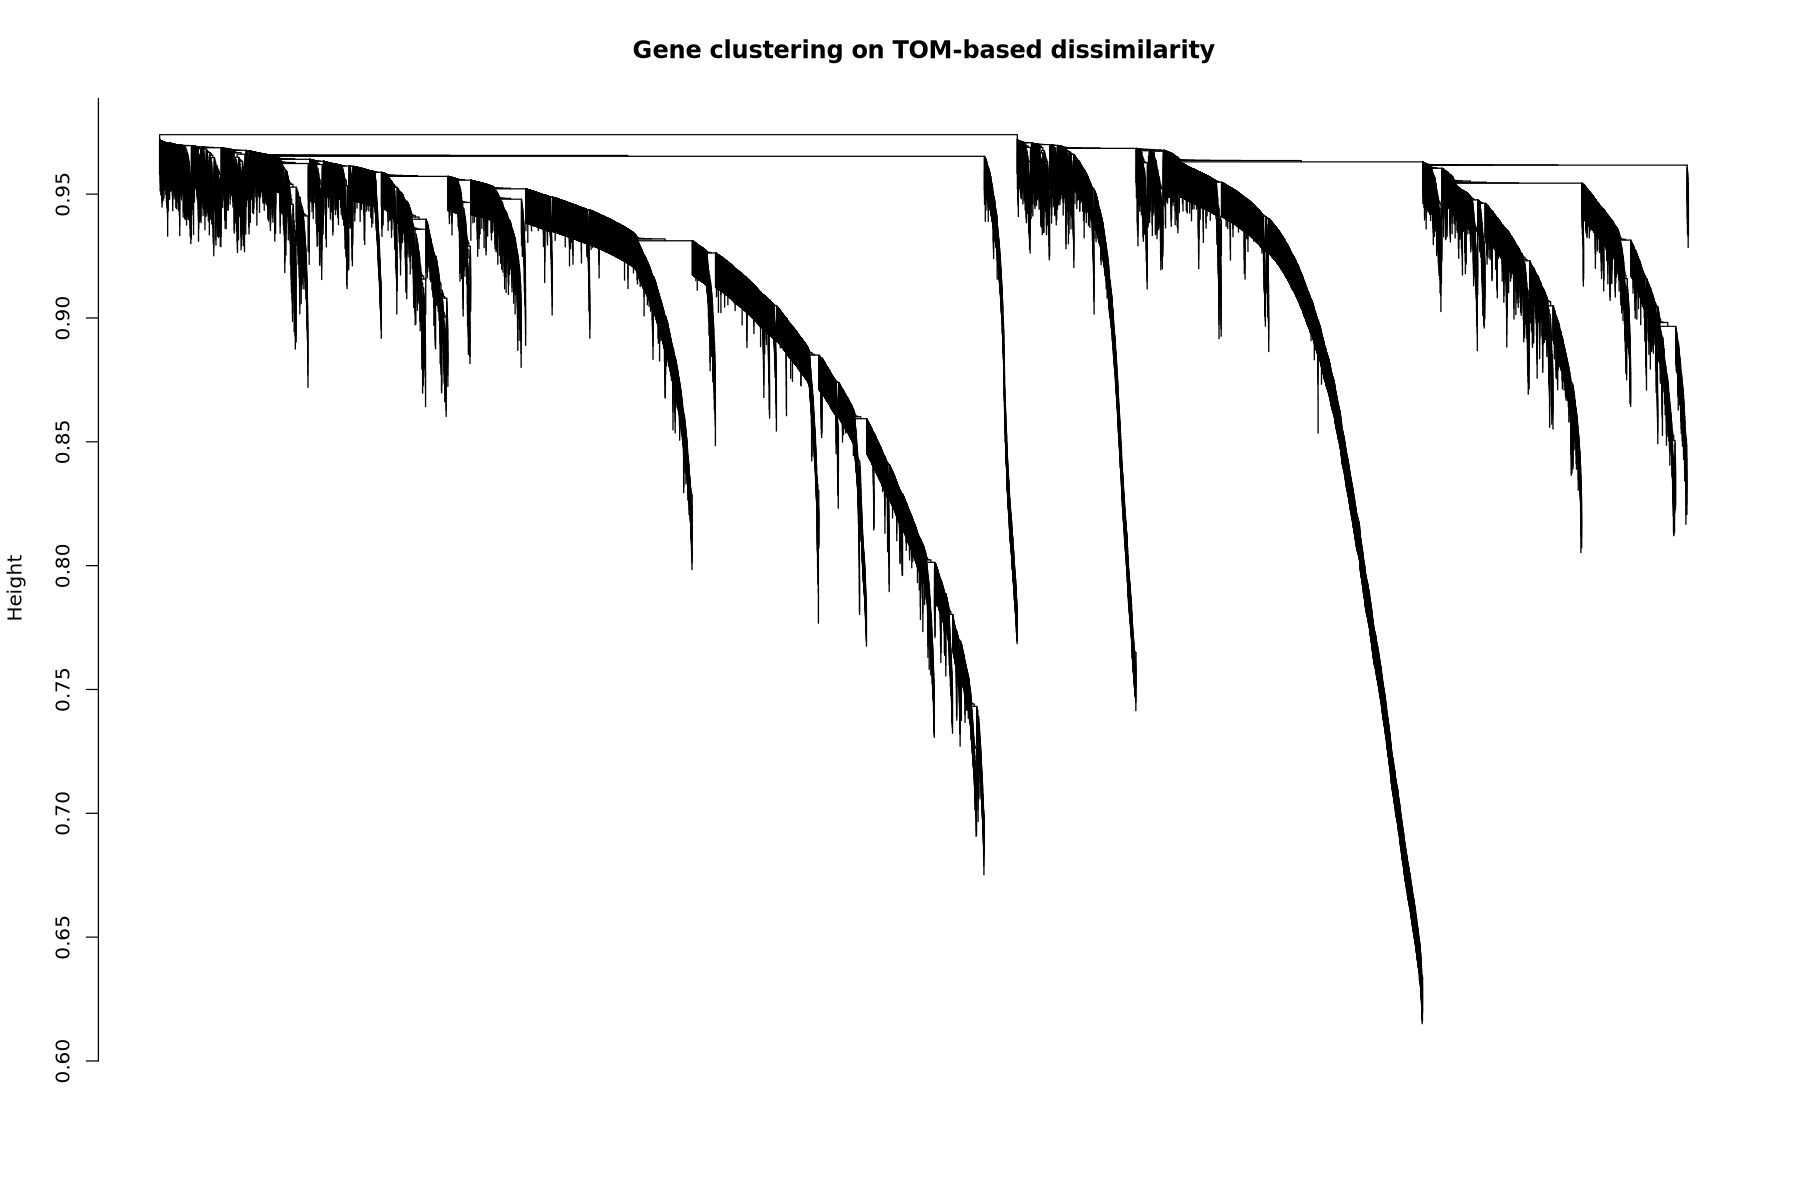

In [25]:
# call hierarchical clustering function
geneTree_sign = hclust(as.dist(dissTOM_sign), method = "average")

# plot the dendrogram
plot(geneTree_sign, xlab="", sub="", main = "Gene clustering on TOM-based dissimilarity",labels = FALSE, hang = 0.04)

each leaf (short vertical line) corresponds to a gene - branches group together densely interconnected, highly co-expressed genes

module identification = cutting branches off the dendrogram

#### E. module identification

set minimum module size - this is the smallest number of genes allowed to be put into a module 

then use Dynamic Tree Cut which is the default method for branch cutting and module detection

In [26]:
# setting the min module size to half of what I have been using (100)
minModuleSize <- 50

## SIGNED
# Module identification using dynamic tree cut:
dynamicMods_sign <- cutreeDynamic(dendro = geneTree_sign, distM = dissTOM_sign, 
                             deepSplit = 2, pamRespectsDendro = FALSE,
                             minClusterSize = minModuleSize)
table(dynamicMods_sign) # number of genes per module

 ..cutHeight not given, setting it to 0.972  ===>  99% of the (truncated) height range in dendro.
 ..done.


dynamicMods_sign
   1    2    3    4    5    6    7    8    9   10   11   12   13   14   15   16 
4449 3378 3150 1641 1377  978  933  842  448  430  424  389  381  217  167  146 
  17   18   19 
 146  136   92 

15 modules generated

convert numeric network to colors and plots dendrogram:

dynamicColors_sign
       black         blue        brown         cyan        green  greenyellow 
         933         3378         3150          217         1377          424 
      grey60    lightcyan   lightgreen  lightyellow      magenta midnightblue 
         146          146          136           92          448          167 
        pink       purple          red       salmon          tan    turquoise 
         842          430          978          381          389         4449 
      yellow 
        1641 

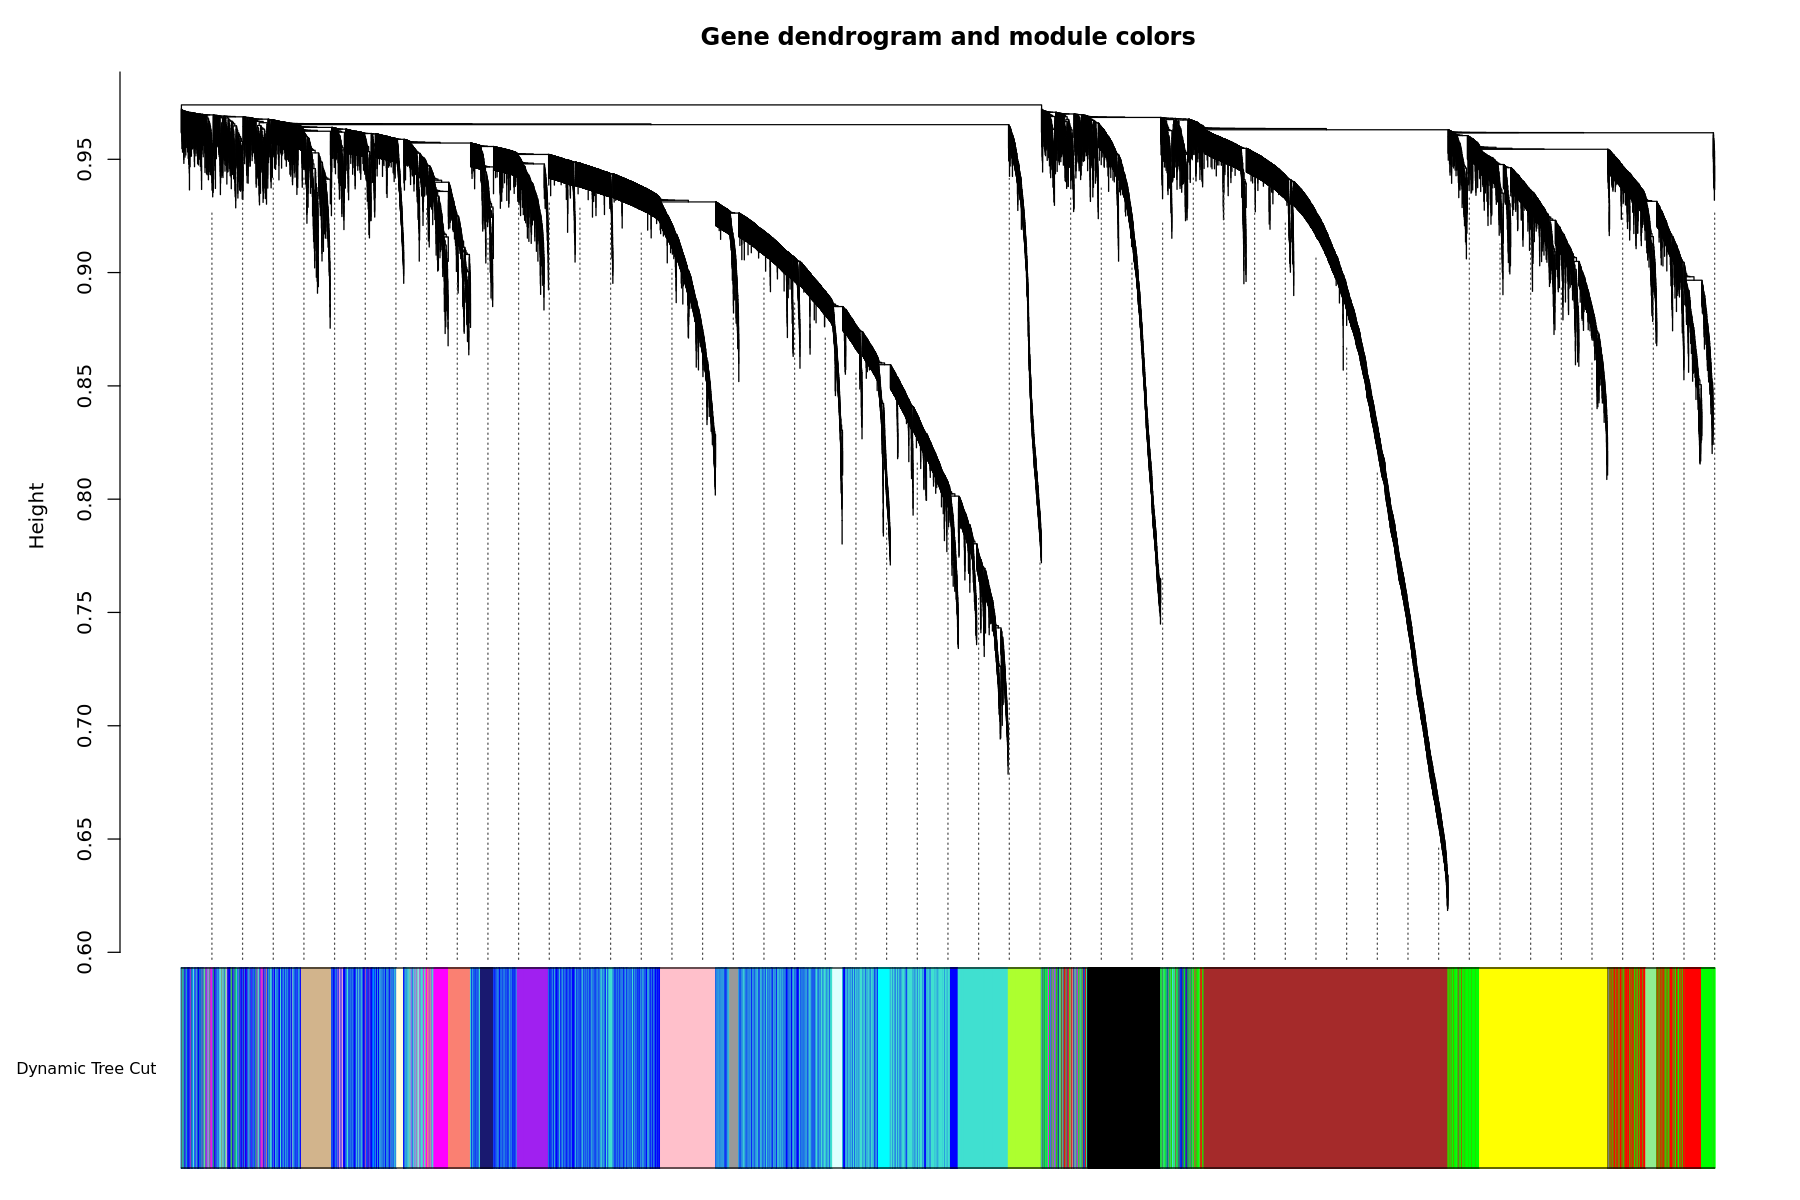

In [27]:
## SIGNED
# Convert numeric lables into colors
dynamicColors_sign <- labels2colors(dynamicMods_sign)
table(dynamicColors_sign)

# Plot the dendrogram and colors underneath
plotDendroAndColors(geneTree_sign, dynamicColors_sign, "Dynamic Tree Cut",
                    dendroLabels = FALSE, hang = 0.03,
                    addGuide = TRUE, guideHang = 0.05,
                    main = "Gene dendrogram and module colors")


#### F. merging modules whose GE profiles are similar

this is based on eigengenes, which is the first principal component of a given a gene expression matrix/module that acts as a representative summary profile for a gene module or cluster

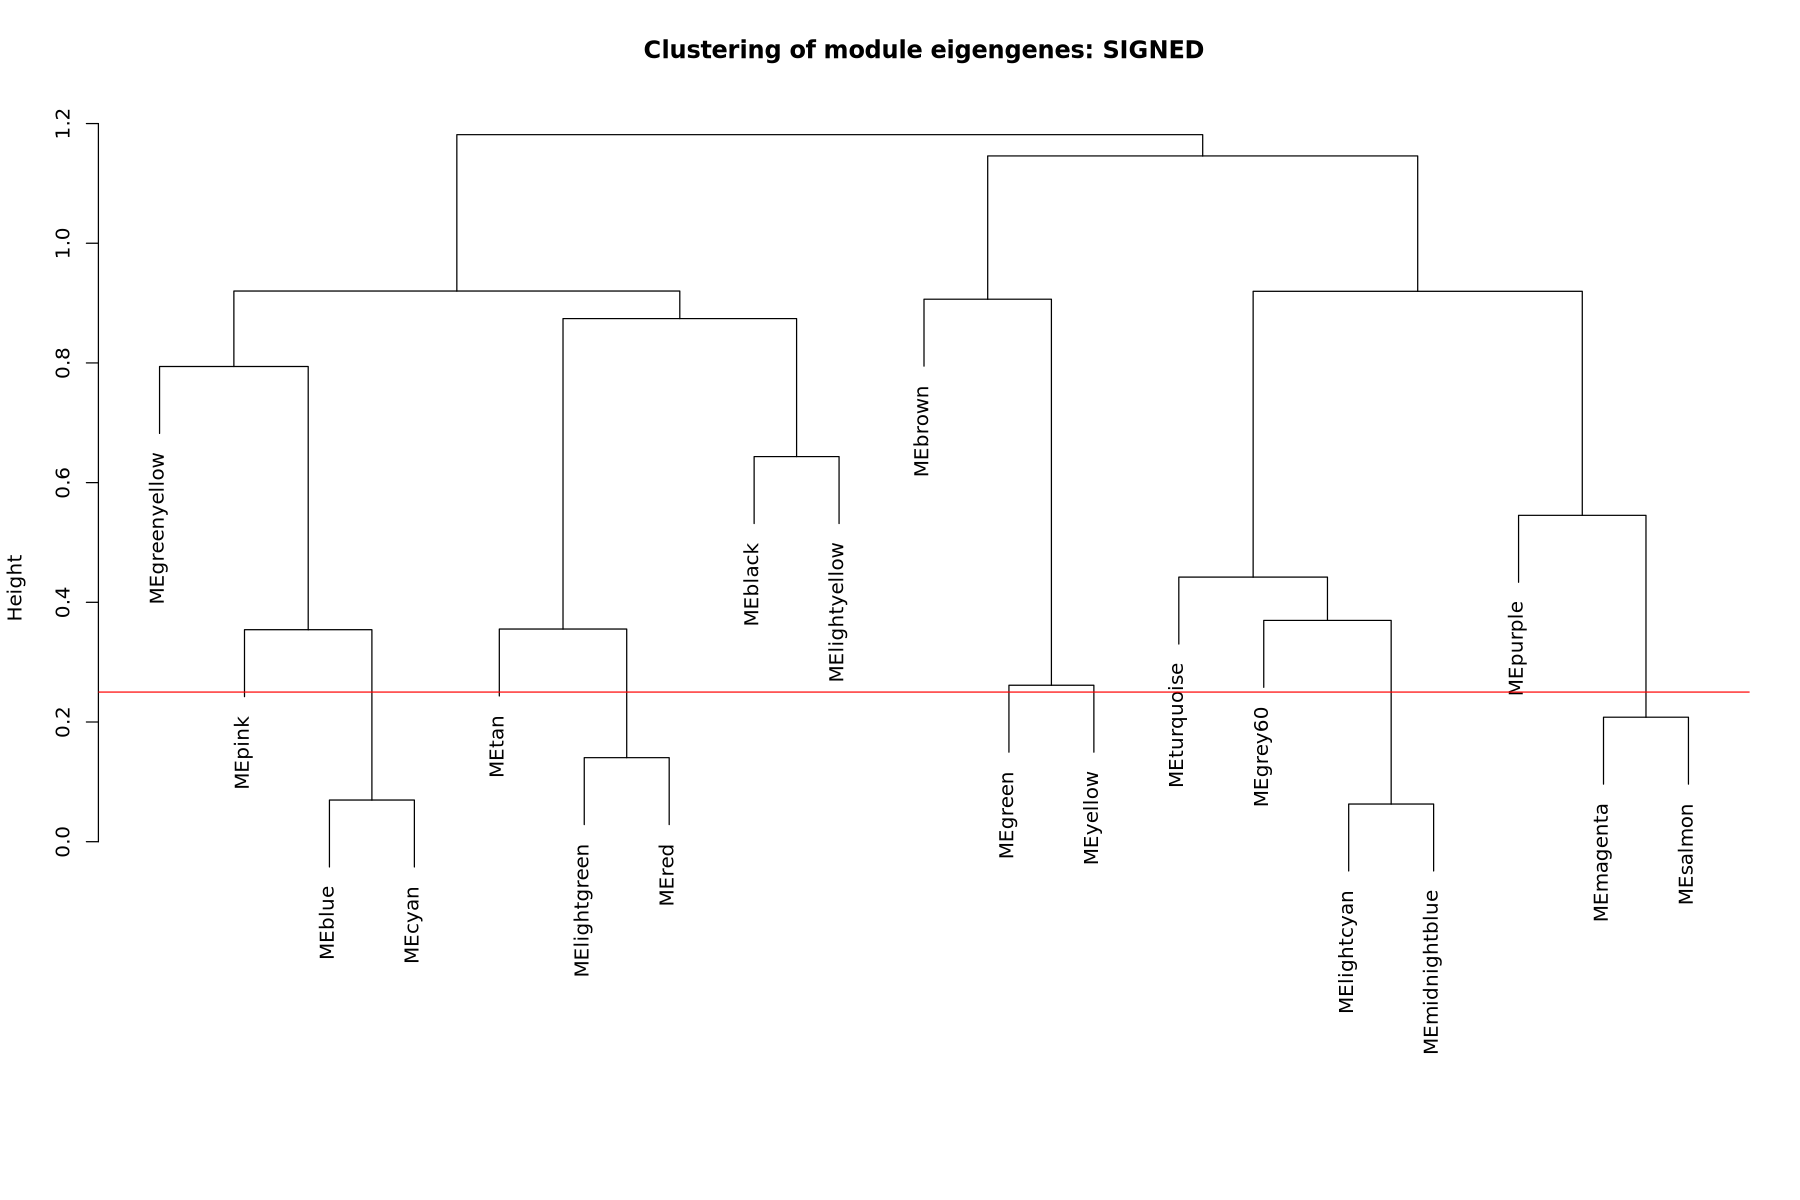

In [28]:
## SIGNED
# Calculate eigengenes
MEList_sign <- moduleEigengenes(dataExpr, colors = dynamicColors_sign)
MEs_sign <- MEList_sign$eigengenes

# Calculate dissimilarity of module eigengenes
MEDiss_sign <- 1-cor(MEs_sign)

# Cluster module eigengenes
METree_sign <- hclust(as.dist(MEDiss_sign), method = "average")

# Plot the result

# height cutoff of 0.25 - corresponds to a correlation of 0.75 to merge
MEDissThres <- 0.25

# Plot the cut line into the dendrogram
plot(METree_sign, main = "Clustering of module eigengenes: SIGNED", xlab = "", sub = "")
abline(h=MEDissThres, col = "red")

any branch with more than 75% correlation are related and will be merged - so green and greenyellow modules will be merged (but it's right on the line, so maybe not)

 mergeCloseModules: Merging modules whose distance is less than 0.25
   multiSetMEs: Calculating module MEs.
     Working on set 1 ...
     moduleEigengenes: Calculating 19 module eigengenes in given set.
   multiSetMEs: Calculating module MEs.
     Working on set 1 ...
     moduleEigengenes: Calculating 15 module eigengenes in given set.
   Calculating new MEs...
   multiSetMEs: Calculating module MEs.
     Working on set 1 ...
     moduleEigengenes: Calculating 15 module eigengenes in given set.


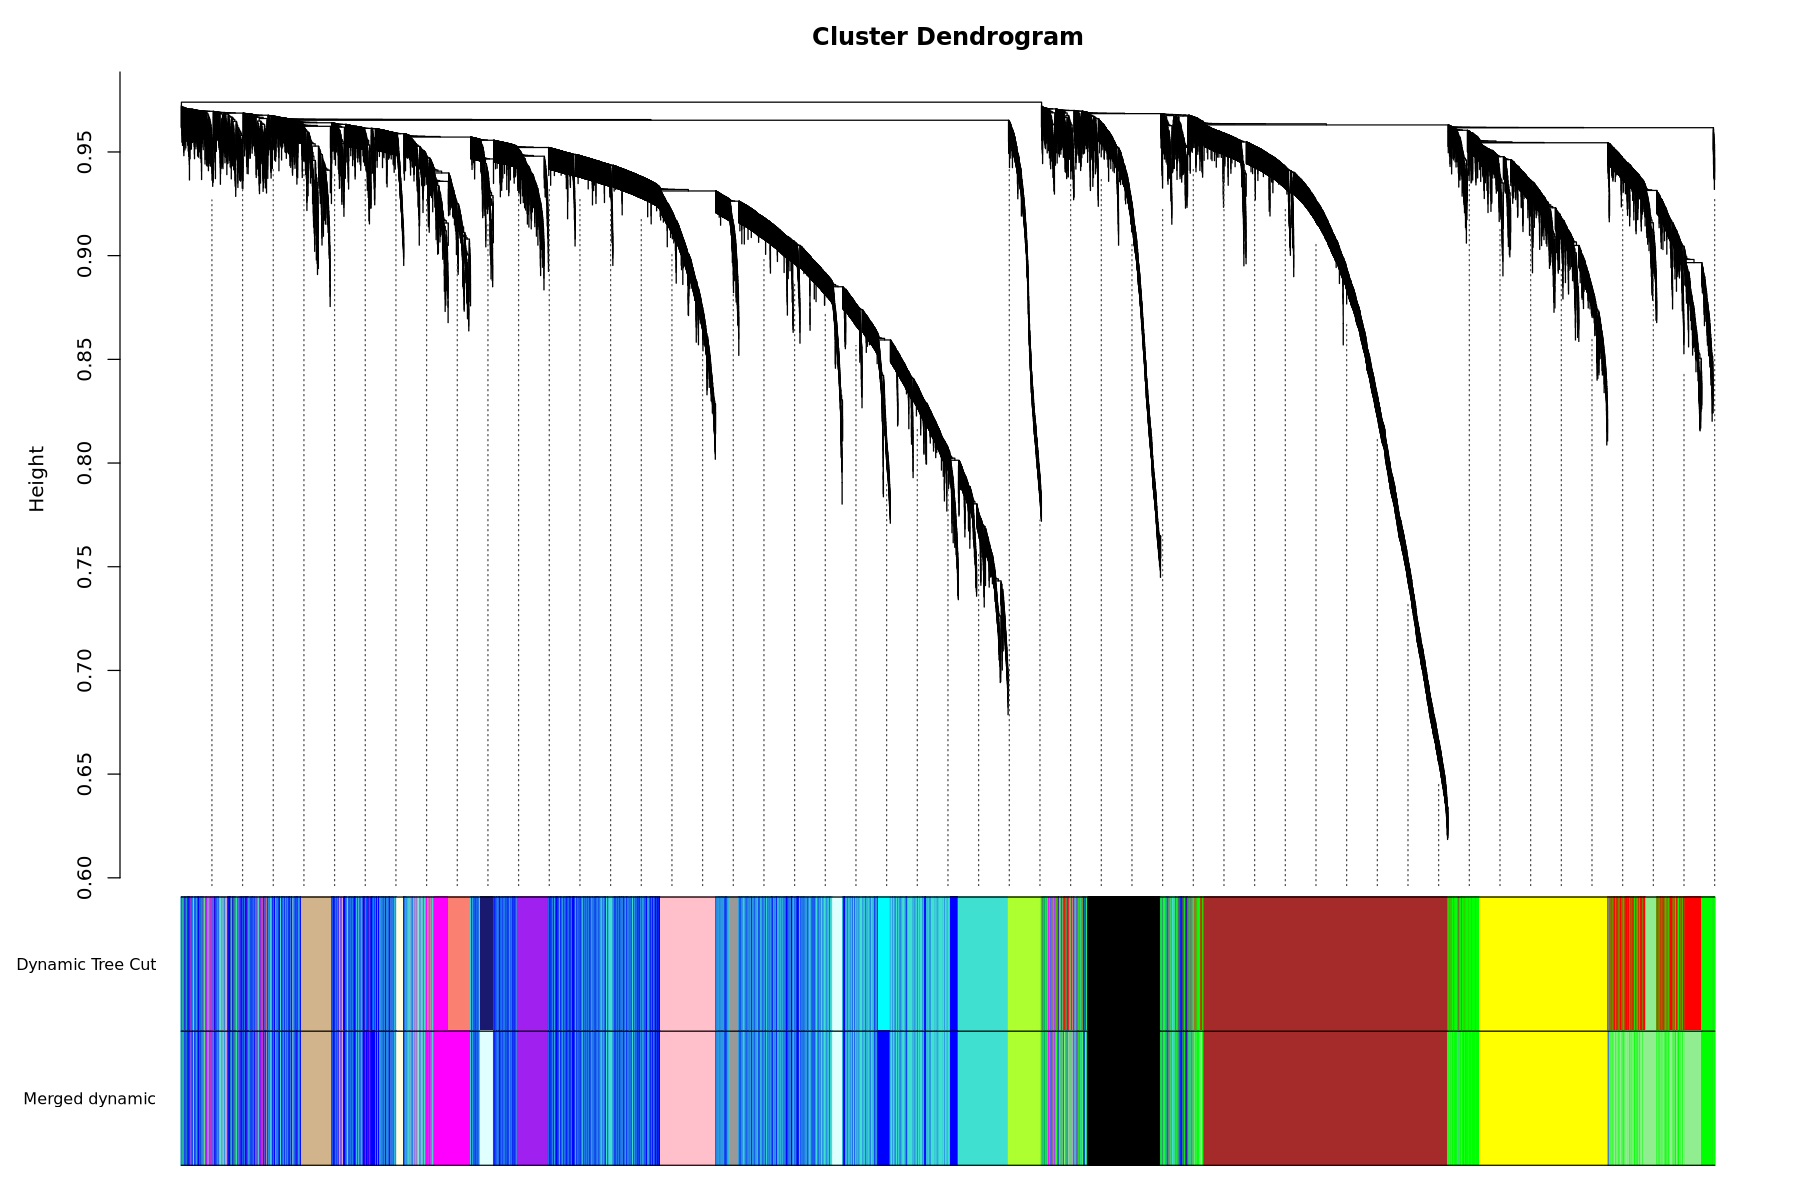

In [29]:
## SIGNED
# Call an automatic merging function
merge_sign <- mergeCloseModules(dataExpr, dynamicColors_sign, cutHeight = MEDissThres, verbose = 3)

# The merged module colors
mergedColors_sign <- merge_sign$colors

# Eigengenes of the new merged modules:
mergedMEs_sign <- merge_sign$newMEs

# plot merged module colors
plotDendroAndColors(geneTree_sign, cbind(dynamicColors_sign, mergedColors_sign), 
                    c("Dynamic Tree Cut", "Merged dynamic"),
                    dendroLabels = FALSE, hang = 0.03,
                    addGuide = TRUE, guideHang = 0.05)

In [30]:
table(mergedColors_sign)

mergedColors_sign
      black        blue       brown       green greenyellow      grey60 
        933        3595        3150        1377         424         146 
  lightcyan  lightgreen lightyellow     magenta        pink      purple 
        313        1114          92         829         842         430 
        tan   turquoise      yellow 
        389        4449        1641 

13 modules ranging from 92 - 7428 genes

(but there's no grey module??)

In [31]:
# Recalculate MEs (module eigengenes) with color labels

MEs0 <- moduleEigengenes(dataExpr, mergedColors_sign)$eigengenes # create module eigengenes

MEs <- orderMEs(MEs0) # order so more similar modules are closer together
head(MEs)

,MEbrown,MEgreen,MEyellow,MEgrey60,MEmagenta,MElightcyan,MEturquoise,MEgreenyellow,MEpurple,MEblue,MEpink,MElightgreen,MEtan,MEblack,MElightyellow
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
B1_Nu_O03,-0.1263136,0.02667732,0.03385525,0.08507338,0.001636938,0.20745680,0.08253664,-0.057846510,-0.10946831,-0.065615853,-0.18325086,-0.04935627,-0.05684139,-0.09123230,-0.0327268577
B2_Nu_O12,0.3025377,-0.05686430,0.04877626,0.00187542,0.006918350,0.04429100,0.05540728,-0.045906305,-0.09901743,0.001760013,-0.17954155,-0.05734813,-0.07859250,-0.10024823,-0.0099316183
B4_Nu_O32,0.1770808,0.12773757,0.04575263,-0.20506658,-0.102373821,-0.22786463,-0.16374729,-0.008226852,-0.05616177,0.016091383,-0.06168324,0.14250860,0.07845518,-0.07785439,0.0001691596
B5_Nu_O36,-0.1468029,0.34242010,0.28864947,-0.17759553,0.002644554,-0.11909569,-0.30679602,-0.060688155,-0.08949981,-0.288605267,-0.18721496,0.30327123,-0.02868319,-0.08179435,-0.0428506825
B6_Nu_O47,-0.1364510,0.27593942,0.34189434,0.10175761,0.133958218,-0.06380407,-0.19794717,-0.042911470,-0.08601515,-0.217641130,-0.17842591,0.02110911,-0.20666240,-0.07722013,0.0179849740
C_W5_W52,-0.1232732,-0.02417803,-0.12777040,0.03208267,0.072403445,-0.01406598,0.16896164,0.060935865,-0.05680605,0.182943086,0.11158270,-0.08649741,0.04041353,0.28428917,0.9443112436


In [32]:
write.csv(MEs, '/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/wgcnaSubset_ModuleEigengenes.csv')

### 3. quantifying module-trait associations
identify modules that are significantly associated with treatment exposures or measured traits (like growth)

#### A. read in and format metadata

**treatment data**

I don't think I need this code - already read in meta data above
```
# read in phase info
dataMeta <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/sample_metaData.csv')

# keep only samples seen in dataExpr
dataMeta <- dataMeta[dataMeta$Sample %in% rownames(dataExpr),] 

# set sample as rownames
rownames(dataMeta) <- dataMeta$Sample

# add phase info
dataMeta <- dataMeta %>%
mutate(Phase_oys = case_when(
    # if phase 2 treatment is NA, it's a phase 1 oyster
    is.na(Phase2_treatment) ~ 1,
    # otherwise, it's a phase 2 oyster
    .default = 2)
       )

# check it out
dim(dataMeta)
head(dataMeta)
```

In [33]:
head(meta_subset)

,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep,complete_trtmt
,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<chr>
B1_Nu_O03,both,warm,hypoxic,1,NA,NA,NA,NA,both_NA
B2_Nu_O12,both,warm,hypoxic,2,NA,NA,NA,NA,both_NA
B3_Nu_O24,both,warm,hypoxic,3,NA,NA,NA,NA,both_NA
B4_Nu_O32,both,warm,hypoxic,4,NA,NA,NA,NA,both_NA
B5_Nu_O36,both,warm,hypoxic,5,NA,NA,NA,NA,both_NA
B6_Nu_O47,both,warm,hypoxic,6,NA,NA,NA,NA,both_NA


In [34]:
meta2 <- meta %>% 
# add phase info
mutate(Phase_oys = case_when(
    # if phase 2 treatment is NA, it's a phase 1 oyster
    is.na(Phase2_treatment) ~ 1,
    # otherwise, it's a phase 2 oyster
    .default = 2)) %>%
select(recent_expo, recent_temp, recent_DO, Phase_oys)

head(meta2)

,recent_expo,recent_temp,recent_DO,Phase_oys
,<chr>,<chr>,<chr>,<dbl>
B1_Nu_O03,both,warm,hypoxic,1
B2_Nu_O12,both,warm,hypoxic,1
B4_Nu_O32,both,warm,hypoxic,1
B5_Nu_O36,both,warm,hypoxic,1
B6_Nu_O47,both,warm,hypoxic,1
C_W5_W52,warm,warm,normoxic,2


values have to be numerical, so going to create a code for my treatments:

**temperature**
1. ambient
2. warm

**dissolved oxygen**
1. normoxic
2. hypoxic

In [35]:
# set factors
meta2$recent_temp <- factor(meta2$recent_temp, c('ambient', 'warm'))
meta2$recent_DO <- factor(meta2$recent_DO, c('normoxic', 'hypoxic'))

# convert categorical to numerical code for treatment info
meta2$temp_code <- as.numeric(factor(meta2$recent_temp))
meta2$DO_code <- as.numeric(factor(meta2$recent_DO))

metaData <- meta2 


dim(metaData)
head(metaData)


[1] 45  6

,recent_expo,recent_temp,recent_DO,Phase_oys,temp_code,DO_code
,<chr>,<fct>,<fct>,<dbl>,<dbl>,<dbl>
B1_Nu_O03,both,warm,hypoxic,1,2,2
B2_Nu_O12,both,warm,hypoxic,1,2,2
B4_Nu_O32,both,warm,hypoxic,1,2,2
B5_Nu_O36,both,warm,hypoxic,1,2,2
B6_Nu_O47,both,warm,hypoxic,1,2,2
C_W5_W52,warm,warm,normoxic,2,2,1


In [36]:
ids <- rownames(metaData)

metaData <- dummy_cols(metaData, select_columns = "recent_expo",
                       remove_selected_columns = FALSE)

rownames(metaData) <- ids

In [37]:
meta_ready <- metaData %>% select(-recent_expo, -recent_temp, -recent_DO)
head(meta_ready)

,Phase_oys,temp_code,DO_code,recent_expo_both,recent_expo_control,recent_expo_hypoxic,recent_expo_warm
,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>
B1_Nu_O03,1,2,2,1,0,0,0
B2_Nu_O12,1,2,2,1,0,0,0
B4_Nu_O32,1,2,2,1,0,0,0
B5_Nu_O36,1,2,2,1,0,0,0
B6_Nu_O47,1,2,2,1,0,0,0
C_W5_W52,2,2,1,0,0,0,1


In [38]:
nSamples <- nrow(dataExpr) # 114 samples
nGenes <- ncol(dataExpr) # 19724 genes

In [39]:
nSamples
nGenes

[1] 45

[1] 19724

not including growth bc I only have growth for phase 1 and 2 oysters at one timepoint each (and not the same timepoints) - but maybe makes sense to incorporate later to better understand shared modules

also not going to include the "binary treatments" right now

In [40]:
head(meta_ready)

,Phase_oys,temp_code,DO_code,recent_expo_both,recent_expo_control,recent_expo_hypoxic,recent_expo_warm
,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>
B1_Nu_O03,1,2,2,1,0,0,0
B2_Nu_O12,1,2,2,1,0,0,0
B4_Nu_O32,1,2,2,1,0,0,0
B5_Nu_O36,1,2,2,1,0,0,0
B6_Nu_O47,1,2,2,1,0,0,0
C_W5_W52,2,2,1,0,0,0,1


#### B. plot heatmaps

In [41]:
moduleTraitCor <- WGCNA::cor(MEs, meta_ready, use = "p") # correlate with traits - using Pearson correlations

moduleTraitPvalue <- corPvalueStudent(moduleTraitCor, nSamples) # compute p-values - uses student's t-distribution

In [42]:
# convert correlation matrix to df
cor.df <- as.data.frame(moduleTraitCor) %>% 
  rownames_to_column(var = "module") %>% 
pivot_longer(cols = !'module',
             names_to = 'Trait',
             values_to = 'Cor')

head(cor.df)

module,Trait,Cor
<chr>,<chr>,<dbl>
MEbrown,Phase_oys,-0.30880044
MEbrown,temp_code,0.16742240
MEbrown,DO_code,-0.07402154
MEbrown,recent_expo_both,-0.01410114
MEbrown,recent_expo_control,-0.12274128
MEbrown,recent_expo_hypoxic,-0.07199776


In [43]:
# convert pvalue matrix to df
pval.df <- as.data.frame(moduleTraitPvalue) %>% 
  rownames_to_column(var = "module") %>% 
pivot_longer(cols = !'module',
             names_to = 'Trait',
             values_to = 'pvalue')

head(pval.df)

module,Trait,pvalue
<chr>,<chr>,<dbl>
MEbrown,Phase_oys,0.0390227
MEbrown,temp_code,0.2716457
MEbrown,DO_code,0.6289236
MEbrown,recent_expo_both,0.9267489
MEbrown,recent_expo_control,0.4218317
MEbrown,recent_expo_hypoxic,0.6383583


In [44]:
# merge the two dfs
module.df <- cor.df %>%
left_join(pval.df, by = c('module', 'Trait')) %>%
# add vol to denote significance for bold labeling
mutate(
    label = sprintf("%.2f\n(%.1g)", Cor, pvalue),
    sig = !is.na(pvalue) & pvalue < 0.05
  )

module.df <- module.df %>%
  mutate(
    Trait = factor(Trait, levels = sort(unique(Trait))),
    module = factor(module, levels = sort(unique(module)))
  )

head(module.df)

module,Trait,Cor,pvalue,label,sig
<fct>,<fct>,<dbl>,<dbl>,<chr>,<lgl>
MEbrown,Phase_oys,-0.30880044,0.0390227,-0.31 (0.04),TRUE
MEbrown,temp_code,0.16742240,0.2716457,0.17 (0.3),FALSE
MEbrown,DO_code,-0.07402154,0.6289236,-0.07 (0.6),FALSE
MEbrown,recent_expo_both,-0.01410114,0.9267489,-0.01 (0.9),FALSE
MEbrown,recent_expo_control,-0.12274128,0.4218317,-0.12 (0.4),FALSE
MEbrown,recent_expo_hypoxic,-0.07199776,0.6383583,-0.07 (0.6),FALSE


In [45]:
unique(module.df$Trait)

[1] Phase_oys           temp_code           DO_code            
[4] recent_expo_both    recent_expo_control recent_expo_hypoxic
[7] recent_expo_warm   
7 Levels: DO_code Phase_oys recent_expo_both ... temp_code

In [46]:
df.clean <- module.df %>%
filter(Trait != 'P1_trtmt_code') %>% # remove treatment interaction
  mutate(Trait = case_match(Trait,
                            "Phase_oys" ~ "Oyster Phase",
                            "temp_code" ~ "Temperature",
                            "DO_code" ~ "Dissolved Oxygen",
                            "recent_expo_both" ~ "Both",
                            "recent_expo_control" ~ "Control",
                            "recent_expo_hypoxic" ~ "Hypoxic",
                            "recent_expo_warm" ~ "Warm"
                            )) # Keeps unchanged values as they are

head(df.clean)

Warning message:
“There was 1 warning in `mutate()`.
ℹ In argument: `Trait = case_match(...)`.
Caused by warning:
! `case_match()` was deprecated in dplyr 1.2.0.
ℹ Please use `recode_values()` instead.”


module,Trait,Cor,pvalue,label,sig
<fct>,<chr>,<dbl>,<dbl>,<chr>,<lgl>
MEbrown,Oyster Phase,-0.30880044,0.0390227,-0.31 (0.04),TRUE
MEbrown,Temperature,0.16742240,0.2716457,0.17 (0.3),FALSE
MEbrown,Dissolved Oxygen,-0.07402154,0.6289236,-0.07 (0.6),FALSE
MEbrown,Both,-0.01410114,0.9267489,-0.01 (0.9),FALSE
MEbrown,Control,-0.12274128,0.4218317,-0.12 (0.4),FALSE
MEbrown,Hypoxic,-0.07199776,0.6383583,-0.07 (0.6),FALSE


In [47]:
df.clean2 <- df.clean %>% mutate(category = case_when(
    Trait == 'Oyster Phase' ~ 'Age',
    Trait %in% c('Temperature', 'Dissolved Oxygen') ~ 'Recent Exposure',
    str_detect(Trait, "Both|Warm|Hypoxic|Control")    ~ "Recent Treatment")) %>%
filter(module != 'MEgrey60')

head(df.clean2)

module,Trait,Cor,pvalue,label,sig,category
<fct>,<chr>,<dbl>,<dbl>,<chr>,<lgl>,<chr>
MEbrown,Oyster Phase,-0.30880044,0.0390227,-0.31 (0.04),TRUE,Age
MEbrown,Temperature,0.16742240,0.2716457,0.17 (0.3),FALSE,Recent Exposure
MEbrown,Dissolved Oxygen,-0.07402154,0.6289236,-0.07 (0.6),FALSE,Recent Exposure
MEbrown,Both,-0.01410114,0.9267489,-0.01 (0.9),FALSE,Recent Treatment
MEbrown,Control,-0.12274128,0.4218317,-0.12 (0.4),FALSE,Recent Treatment
MEbrown,Hypoxic,-0.07199776,0.6383583,-0.07 (0.6),FALSE,Recent Treatment


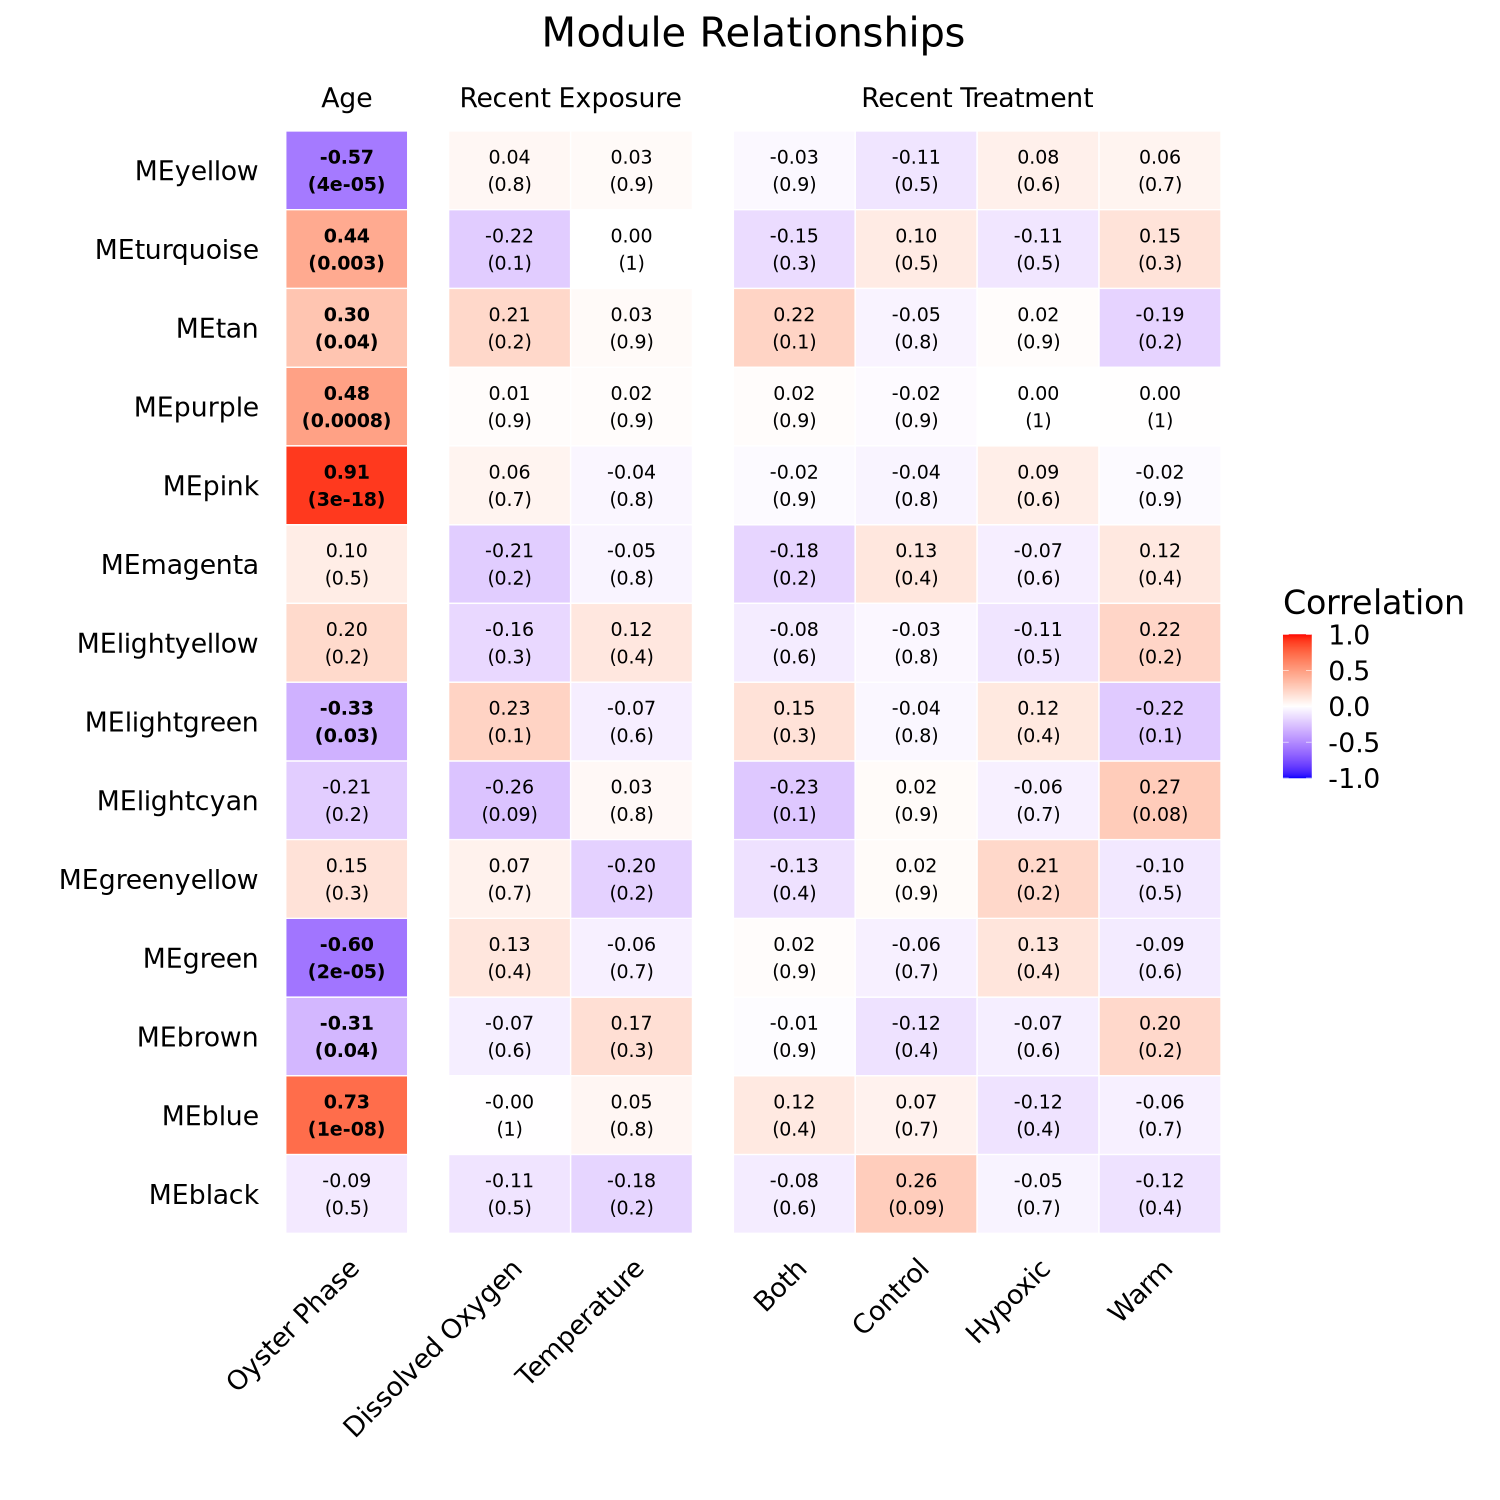

In [48]:
options(repr.plot.width = 12.5, repr.plot.height = 12.5)


#

heatmap1 <- ggplot(df.clean2, aes(x = Trait, y = module, fill = Cor)) +
  geom_tile(color = "white") +
  
  # text annotations
  geom_text(
    aes(
      label = label,
      fontface = ifelse(sig, "bold", "plain")
    ),
    size = 4
  ) +
  
  scale_fill_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    limits = c(-1, 1)
  ) +

  theme_minimal(base_size = 20) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1, color = 'black'),
      axis.text.y = element_text(color = 'black'),
    panel.grid = element_blank(),
      plot.title = element_text(hjust = .5),
      strip.text = element_text(color = 'black')
  ) +

 facet_grid(
    ~ category,
    scales = "free_x",
    space = "free_x"
  ) +
  
  labs(
    title = "Module Relationships",
    x = "",
    y = "",
    fill = "Correlation"
  )

heatmap1

**observations**
- there are no modules correlated with DO/temp or treatments - this tells me that there are not shared responses to DO/temp stress at different ages
    - the transcriptional responses are different to stresses depending on the age of the oyster/when the stress was experienced
- the only significantly correlated modules are those correlated with age
    - and these are really strong correlations - stronger than I've seen in other analyses!
    - positive correlation = higher expression in phase 2 oysters
    - negative correlation = higher expression in phase 1 oysters
    - this reiterates the point that GE is short-term/influenced by the most recent exposure and is plastic in terms of how genes respond at different timepoints in an oyster's life

In [58]:
# Create ME table
MEs_df <- as.data.frame(MEs)
MEs_df$Sample <- rownames(MEs_df)

# format metadata and merge with MEs
dataMeta2 <- meta2 %>% select(-temp_code, -DO_code) 
dataMeta2$Sample <- rownames(dataMeta2)
dim(dataMeta2)

# merge MEs and metadata
MEsPlotting <- merge(dataMeta2, MEs_df, by = 'Sample')

# Melt to long format
MEsPlotting_melt <- reshape2::melt(
  MEsPlotting,
  id.vars = c("Sample",
      "recent_expo",
              "recent_temp",
              "recent_DO",
              "Phase_oys"
             ),
  variable.name = "Module",
  value.name = "Eigengene"
)

MEsPlotting_melt <- MEsPlotting_melt %>%
filter(!grepl('code', Module)) # remove treatment code rows

head(MEsPlotting_melt)

[1] 45  5

,Sample,recent_expo,recent_temp,recent_DO,Phase_oys,Module,Eigengene
,<chr>,<chr>,<fct>,<fct>,<dbl>,<fct>,<dbl>
1,B1_Nu_O03,both,warm,hypoxic,1,MEbrown,-0.1263136
2,B2_Nu_O12,both,warm,hypoxic,1,MEbrown,0.3025377
3,B4_Nu_O32,both,warm,hypoxic,1,MEbrown,0.1770808
4,B5_Nu_O36,both,warm,hypoxic,1,MEbrown,-0.1468029
5,B6_Nu_O47,both,warm,hypoxic,1,MEbrown,-0.1364510
6,C_W5_W52,warm,warm,normoxic,2,MEbrown,-0.1232732


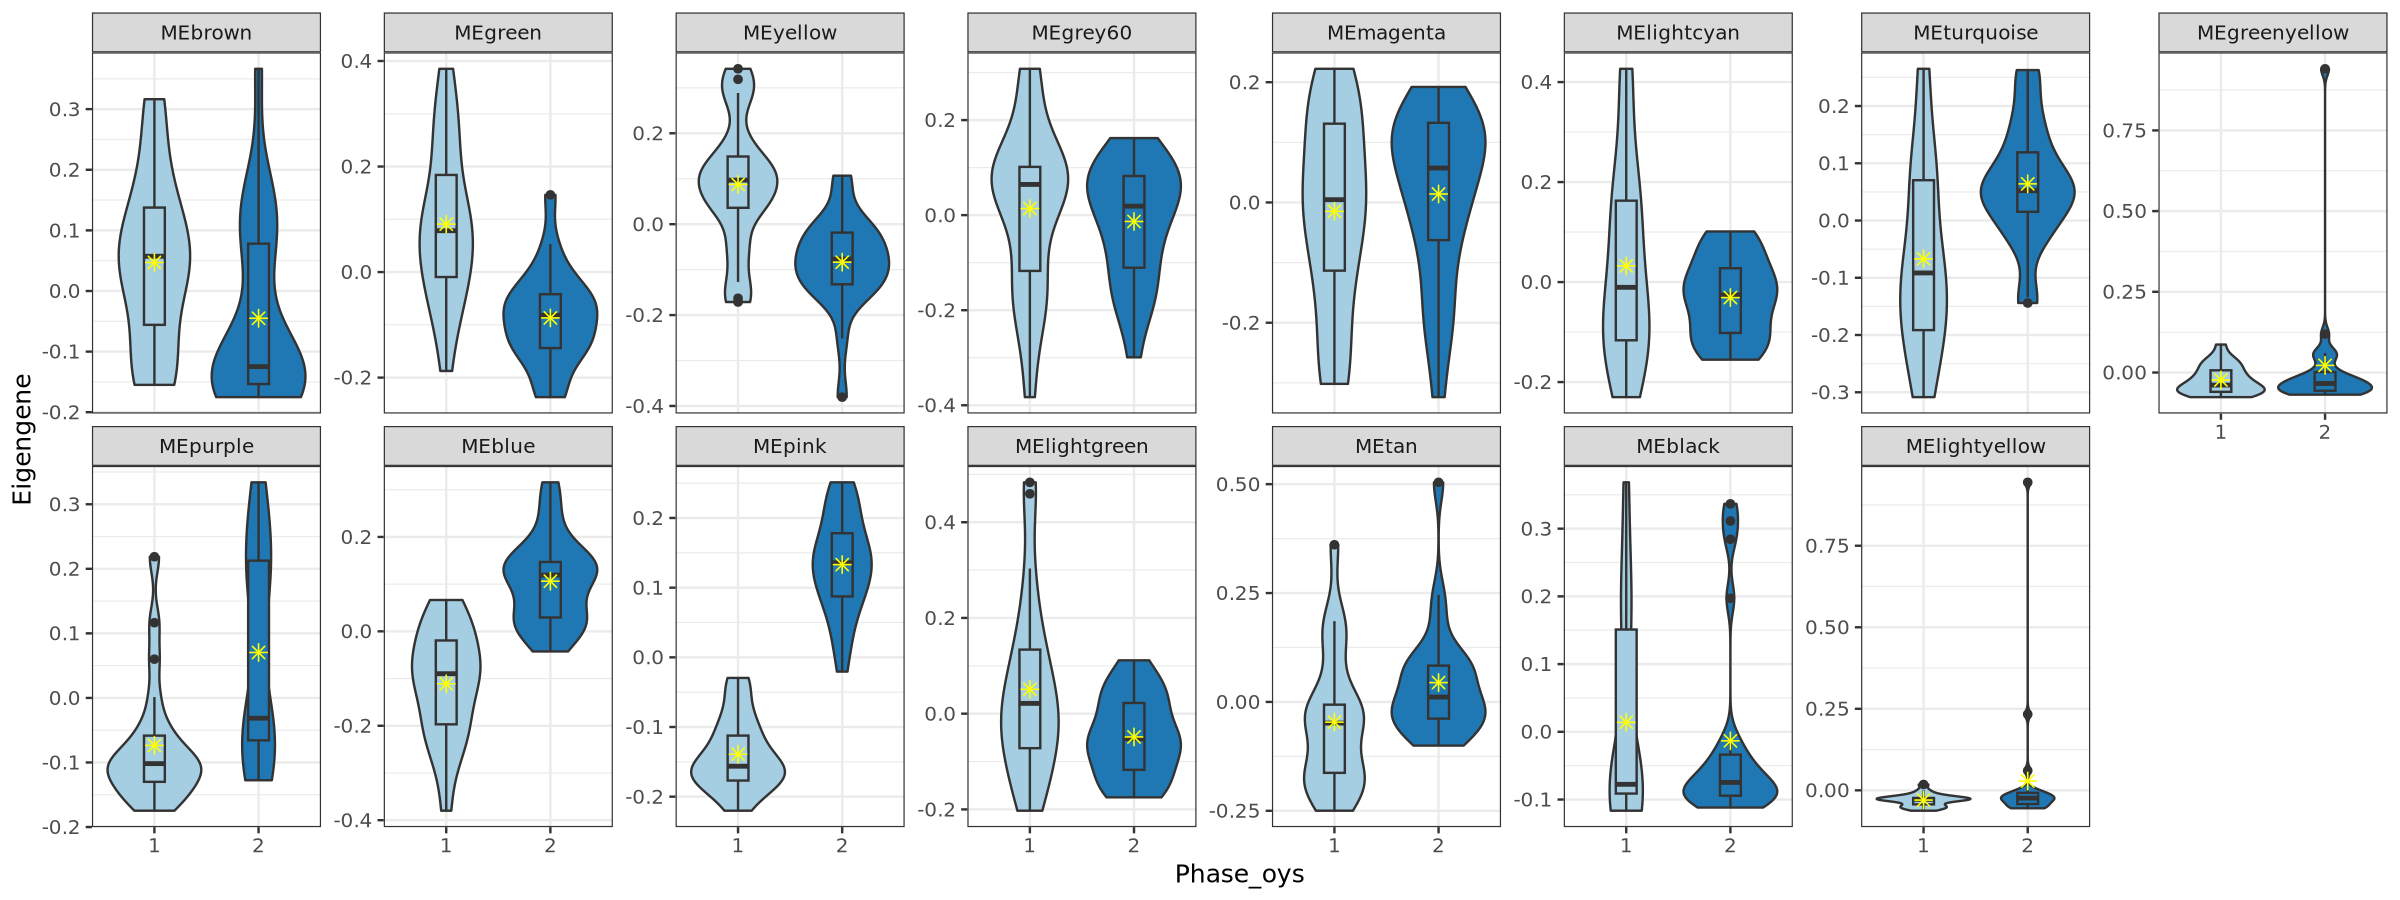

In [67]:
options(repr.plot.height = 7.5, repr.plot.width = 20)

MEsPlotting_melt$Phase_oys <- as.character(MEsPlotting_melt$Phase_oys)

ggplot(MEsPlotting_melt, aes(x = Phase_oys, y = Eigengene, fill = Phase_oys)) +
geom_violin() +
geom_boxplot(width = 0.2) +
stat_summary(
    position = position_dodge(width = 0.75),
    fun = "mean", 
    geom = "point", 
    shape = 8,      # asterick shape
    size = 3,        # Size of the point
    color = "yellow"  # Outline color
  ) +
facet_wrap(~Module, nrow = 2, scales = 'free_y') +
guides(fill = 'none') +
scale_fill_brewer(palette = 'Paired') +
theme_bw(base_size = 15)

### 4. hub genes
those most connected within a gene module

In [83]:
hubGenes <- chooseTopHubInEachModule(dataExpr, # vst expr. matrix
                         mergedColors_sign, # from dendogram above
                         omitColors = "grey", # grey module = genes not assigned to any module
                         power = 5, 
                         type = "signed")

# make into df, assign modules in column
hubGenes.df <- as.data.frame(hubGenes) %>%
mutate(module = rownames(.)) %>%
rename(hubGenes = 'gene')
# remove row names
rownames(hubGenes.df) <- NULL

In [97]:
hub.annot <- merge(hubGenes.df, gtf, by = 'gene') %>% 
filter(!is.na(description)) %>%
mutate(higher_expr = case_when(
    module %in% c('yellow', 'lightgreen', 'green', 'brown') ~ 'Phase 1',
    module %in% c('turquoise', 'tan', 'purple', 'pink', 'blue') ~ 'Phase 2',
    TRUE ~ NA)) %>%
arrange(higher_expr)

hub.annot

gene,module,description,higher_expr
<chr>,<chr>,<chr>,<chr>
LOC111123117,brown,follistatin-related protein 1-like,Phase 1
LOC111126292,lightgreen,death-associated protein 1-like,Phase 1
LOC111134660,green,lysine-specific demethylase 2B-like,Phase 1
LOC111135975,yellow,uncharacterized LOC111135975,Phase 1
LOC111109666,blue,putative NADH dehydrogenase [ubiquinone] 1 alpha subcomplex subunit 12,Phase 2
LOC111113508,purple,uncharacterized LOC111113508,Phase 2
LOC111118318,turquoise,THO complex subunit 4-like,Phase 2
LOC111119090,tan,ubiquitin-conjugating enzyme E2 S-like,Phase 2
LOC111133895,pink,uncharacterized LOC111133895,Phase 2


modules with higher expression in **phase 1**:
- yellow
- lightgreen
- green
- brown

modules with higher expression in **phase 2**:
- turquoise
- tan
- purple
- pink
- blue

### 5. Gene significance (GS) and module membership (MM)
both are critical metrics for identifying hub genes within modules that are associated with specific treatment/traits
- GS = correlates gene expression with treatment/trait
    - high GS (>0.7) indicates the gene is individually associated with the trait/treatment
- MM = how well a gene belongs to a module
    - high MM (>0.7) indicates the gene is central to the module's GE pattern
 
Genes with high MM *and* GS are good candidates for genes of interest
- strong positive correlation between MM and GS indicates the entire module is relevant to the trait, not just a few outlier genes (so can plot MM vs. GS for a specific module)

basically select a module of interest and validate with GS and MM - combine GS and MM to find genes that are highly connected *and* strongly associated with the treatment/trait

In [84]:
modNames <- substring(names(MEs), 3)
modNames

[1] "brown"       "green"       "yellow"      "grey60"      "magenta"    
 [6] "lightcyan"   "turquoise"   "greenyellow" "purple"      "blue"       
[11] "pink"        "lightgreen"  "tan"         "black"       "lightyellow"

#### module membership
MM is the same across all treatments

In [85]:
geneModuleMembership = as.data.frame(cor(dataExpr, MEs, use = "p"))
MMPvalue = as.data.frame(corPvalueStudent(as.matrix(geneModuleMembership), nSamples))

names(geneModuleMembership) = paste("MM", modNames, sep="")
names(MMPvalue) = paste("p.MM", modNames, sep="")

In [86]:
head(geneModuleMembership)

,MMbrown,MMgreen,MMyellow,MMgrey60,MMmagenta,MMlightcyan,MMturquoise,MMgreenyellow,MMpurple,MMblue,MMpink,MMlightgreen,MMtan,MMblack,MMlightyellow
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LOC144621260,0.52130936,-0.07001977,0.06078252,0.12601615,0.23705440,0.04502247,0.05262517,-0.243663728,-0.04626566,0.06437416,-0.12373695,-0.1746286,-0.21846163,0.359995578,0.2499328
LOC144621269,0.95854569,0.09384332,0.09154801,-0.15277781,-0.25130704,0.13831195,-0.19872274,-0.004721947,-0.21079326,-0.16567972,-0.31523112,0.1246694,0.01052625,0.005500375,-0.1647214
LOC111120925,0.14026876,0.05433510,-0.19500455,-0.36269363,-0.30073822,-0.15155786,-0.17199651,0.148164131,0.01207836,0.11388703,-0.04604726,0.3740263,0.34744260,0.930622268,0.1872893
LOC144621283,-0.09606970,-0.62731495,-0.60514254,0.05698764,-0.04873685,0.16361525,0.58097527,0.306101656,0.24127605,0.71622647,0.40722135,-0.3344669,0.27475596,0.068739224,0.3138972
LOC144621276,0.05863365,-0.72649044,-0.83041617,-0.18186655,-0.17650217,-0.03803452,0.57098603,0.066961082,0.20805683,0.87206661,0.48010570,-0.2694058,0.46301703,0.071177400,0.1230955
LOC111115920,-0.14129497,0.13688903,0.34236071,0.16243129,0.25949960,0.02637609,-0.04672040,-0.094459039,-0.01764933,-0.19702380,-0.08896998,-0.1553637,-0.30854768,-0.207578270,0.1053212


#### gene significance
calculated for each treatment combination

In [87]:
##### GS #####
# calc GS for every gene and trait
geneTraitSignificance_df <- as.data.frame(
  WGCNA::cor(
    dataExpr,
    meta_ready,
    use = "p"
  )
)

# add prefix to column names
colnames(geneTraitSignificance_df) <- paste0(
  "GS.",
  colnames(geneTraitSignificance_df)
)

##### PVAL #####
# calc pvalue
GSPvalue_df <- as.data.frame(
  corPvalueStudent(
    as.matrix(geneTraitSignificance_df),
    nSamples = nrow(dataExpr)
  )
)

# add prefix to column names
colnames(GSPvalue_df) <- paste0(
  "p.GS.",
  colnames(GSPvalue_df)
)

# check it out
head(geneTraitSignificance_df)
head(GSPvalue_df)

,GS.Phase_oys,GS.temp_code,GS.DO_code,GS.recent_expo_both,GS.recent_expo_control,GS.recent_expo_hypoxic,GS.recent_expo_warm
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LOC144621260,-0.05863409,0.2030722,-0.163921269,0.00872477,-0.03681398,-0.19939143,0.22107144
LOC144621269,-0.31994027,0.2001027,-0.146284772,-0.03783631,-0.10043513,-0.13231629,0.26296400
LOC111120925,-0.07626536,-0.1227264,-0.072319026,0.03194097,0.25880996,-0.11605957,-0.16976949
LOC144621283,0.43757481,0.1528333,-0.101086294,0.11836101,0.05817095,-0.23594055,0.05773477
LOC144621276,0.56437341,0.2467170,0.006155075,0.21881169,-0.07531895,-0.21165236,0.06623924
LOC111115920,-0.06263278,0.2109318,0.229110664,0.35342260,-0.15841716,-0.08693024,-0.10503022


,p.GS.GS.Phase_oys,p.GS.GS.temp_code,p.GS.GS.DO_code,p.GS.GS.recent_expo_both,p.GS.GS.recent_expo_control,p.GS.GS.recent_expo_hypoxic,p.GS.GS.recent_expo_warm
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LOC144621260,0.702023390,0.1809276,0.2819395,0.95463952,0.81026235,0.1891323,0.14445868
LOC144621269,0.032153388,0.1875266,0.3376266,0.80509427,0.51153901,0.3862457,0.08094345
LOC111120925,0.618531114,0.4218885,0.6368568,0.83500247,0.08603769,0.4477247,0.26488563
LOC144621283,0.002647954,0.3162033,0.5087912,0.43870924,0.70426959,0.1186845,0.70638726
LOC144621276,0.000053912,0.1022963,0.9679911,0.14871242,0.62290571,0.1627978,0.66551053
LOC111115920,0.682736350,0.1642674,0.1300538,0.01724048,0.29863199,0.5701622,0.49230935


In [88]:
colnames(geneTraitSignificance_df)

[1] "GS.Phase_oys"           "GS.temp_code"           "GS.DO_code"            
[4] "GS.recent_expo_both"    "GS.recent_expo_control" "GS.recent_expo_hypoxic"
[7] "GS.recent_expo_warm"

In [91]:
# 1. Create a data frame for gene information
# Ensure the names of the vector match your gene names
gene_info <- data.frame(
  Gene = colnames(dataExpr),
  ModuleColor = mergedColors_sign
)

# 2. Bind it with  MM and GS dataframes
# (Assuming these have genes as row names in the same order)
final_results <- cbind(gene_info, geneTraitSignificance_df, GSPvalue_df, geneModuleMembership)


# 3. Take a look
head(final_results)

,Gene,ModuleColor,GS.Phase_oys,GS.temp_code,GS.DO_code,GS.recent_expo_both,GS.recent_expo_control,GS.recent_expo_hypoxic,GS.recent_expo_warm,p.GS.GS.Phase_oys,⋯,MMlightcyan,MMturquoise,MMgreenyellow,MMpurple,MMblue,MMpink,MMlightgreen,MMtan,MMblack,MMlightyellow
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LOC144621260,LOC144621260,brown,-0.05863409,0.2030722,-0.163921269,0.00872477,-0.03681398,-0.19939143,0.22107144,0.702023390,⋯,0.04502247,0.05262517,-0.243663728,-0.04626566,0.06437416,-0.12373695,-0.1746286,-0.21846163,0.359995578,0.2499328
LOC144621269,LOC144621269,brown,-0.31994027,0.2001027,-0.146284772,-0.03783631,-0.10043513,-0.13231629,0.26296400,0.032153388,⋯,0.13831195,-0.19872274,-0.004721947,-0.21079326,-0.16567972,-0.31523112,0.1246694,0.01052625,0.005500375,-0.1647214
LOC111120925,LOC111120925,black,-0.07626536,-0.1227264,-0.072319026,0.03194097,0.25880996,-0.11605957,-0.16976949,0.618531114,⋯,-0.15155786,-0.17199651,0.148164131,0.01207836,0.11388703,-0.04604726,0.3740263,0.34744260,0.930622268,0.1872893
LOC144621283,LOC144621283,blue,0.43757481,0.1528333,-0.101086294,0.11836101,0.05817095,-0.23594055,0.05773477,0.002647954,⋯,0.16361525,0.58097527,0.306101656,0.24127605,0.71622647,0.40722135,-0.3344669,0.27475596,0.068739224,0.3138972
LOC144621276,LOC144621276,blue,0.56437341,0.2467170,0.006155075,0.21881169,-0.07531895,-0.21165236,0.06623924,0.000053912,⋯,-0.03803452,0.57098603,0.066961082,0.20805683,0.87206661,0.48010570,-0.2694058,0.46301703,0.071177400,0.1230955
LOC111115920,LOC111115920,magenta,-0.06263278,0.2109318,0.229110664,0.35342260,-0.15841716,-0.08693024,-0.10503022,0.682736350,⋯,0.02637609,-0.04672040,-0.094459039,-0.01764933,-0.19702380,-0.08896998,-0.1553637,-0.30854768,-0.207578270,0.1053212


In [92]:
write.csv(final_results, '/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/compare_phases/outputs/wgcna_GeneInfo.csv', row.names = FALSE)

# I STOPPED HERE

## 5. MEs and geochem data
I now have some [geochem data](https://github.com/jgmcdonough/CE24_RNA-seq/tree/main/metaData/geochem) to play with - but this only includes control and hypoxic oysters from phase 1 (C, H) and 2 (CC, HC, HH)

### geochem data

In [122]:
geochem <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/geochem/geochem_data.csv') %>%
select(-X)

# for now, just going to focus on spot A (where the extrapallial fluid is)
geochemA <- geochem %>% filter(spot == 'A')

dim(geochemA)
head(geochemA)

[1] 30 28

,sample_list,seq_name,phase,spot,shell_growth,phase_1,phase_2,phase_1_condition,phase_2_condition,Na,⋯,U,Na.Ca,Mg.Ca,S.Ca,K.Ca,Mn.Ca,Fe.Ca,Sr.Ca,Ba.Ca,U.Ca
,<chr>,<chr>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,p1_B14_A,H2_Nu_B14,1,A,152.16474,Hyp,,Hyp,,1.97284e-09,⋯,7.75928e-16,0.006951856,0.009546778,-0.031513647,7.42662e-05,1.20391e-04,1.16901e-04,0.000978584,2.90268e-06,2.73421e-09
2,p1_B18_A,H3_Nu_B18,1,A,135.69738,Hyp,,Hyp,,1.93551e-09,⋯,8.33857e-16,0.006805677,0.006899245,-0.010119833,2.87050e-05,8.46998e-05,8.90617e-05,0.001058366,3.07303e-06,2.93202e-09
3,p1_B28_A,H4_Nu_B28,1,A,69.51126,Hyp,,Hyp,,1.71403e-09,⋯,9.19077e-16,0.006205682,0.007808937,0.005459457,-1.63703e-05,1.19781e-04,1.79540e-04,0.001169874,3.73167e-06,3.32753e-09
4,p1_B35_A,H5_Nu_B35,1,A,47.02698,Hyp,,Hyp,,2.57768e-09,⋯,1.22550e-15,0.008331718,0.004737459,0.016822834,9.87896e-05,1.09617e-04,1.46830e-04,0.001466859,5.78570e-06,3.96112e-09
5,p1_B35_B,H5_Nu_B35,1,A,47.02698,Hyp,,Hyp,,1.30272e-09,⋯,2.04963e-15,0.009029580,0.006327355,-1.109678248,-4.47691e-04,2.73016e-04,1.24264e-02,0.001529136,5.55207e-06,1.42067e-08
6,p1_B45_B,H6_Nu_B45,1,A,108.62124,Hyp,,Hyp,,2.42552e-09,⋯,3.99764e-16,0.008066405,0.006490027,0.130696637,1.43423e-04,8.21925e-05,1.08986e-04,0.001177869,3.19130e-06,1.32947e-09


In [123]:
unique(geochemA$spot)

[1] "A"

### pull expression data

In [124]:
dataExpr_geo <- dataExpr[rownames(dataExpr) %in% geochemA$seq_name,]

dim(dataExpr_geo)
head(dataExpr_geo)

[1]    26 19724

,LOC144621260,LOC144621269,LOC111120925,LOC144621283,LOC144621276,LOC111115920,LOC144621308,LOC111112629,LOC111102827,LOC111102829,⋯,LOC144621545,LOC111110910,LOC111110817,LOC111111216,LOC111111215,LOC111111213,LOC111114497,LOC111114498,LOC111112304,LOC144621888
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
C1_H2_W13,11.34430,8.648366,8.591124,10.52902,13.33766,9.422838,9.002532,9.982514,10.94972,10.415205,⋯,9.594800,10.005568,9.109857,9.600811,9.914542,13.33035,9.262391,11.62891,11.08286,8.904057
C1_H6_W62,10.79810,10.389895,9.159850,10.95729,13.57999,9.452645,9.016238,9.432458,11.10562,9.911612,⋯,9.801634,10.550328,9.122148,9.625460,9.360918,13.12339,9.611875,11.28601,10.50313,8.725995
C1_Nu_W01,11.36361,12.844308,8.875814,10.45791,12.82327,9.598656,9.160949,9.795793,10.78538,10.017719,⋯,9.259380,10.520125,9.315554,10.042869,10.113038,13.21026,9.154591,11.23815,10.81617,9.151384
C1_Nu_W05,11.55916,11.271695,9.773815,10.23990,13.49418,9.344255,8.870907,10.552234,11.06659,9.972675,⋯,9.585958,9.952062,9.069769,9.283457,9.522827,13.81508,9.181437,12.00511,10.71295,9.124662
C2_C1_W03,11.57057,9.726423,8.666304,10.43991,13.61526,9.479297,8.741434,9.245285,10.23777,9.644133,⋯,8.909477,10.697001,10.078122,9.965202,9.872431,13.55457,9.499957,11.99751,10.67272,9.119826
C2_H1_W04,11.78197,12.732518,8.942956,10.60950,13.86869,9.156224,9.049070,10.144676,10.71706,9.853558,⋯,9.469762,10.260025,9.339183,9.752950,9.626852,13.81717,9.669952,11.77238,10.75101,8.727675


there are four samples missing - what are they?

In [125]:
geochemA[!geochemA$seq_name %in% rownames(dataExpr),]

,sample_list,seq_name,phase,spot,shell_growth,phase_1,phase_2,phase_1_condition,phase_2_condition,Na,⋯,U,Na.Ca,Mg.Ca,S.Ca,K.Ca,Mn.Ca,Fe.Ca,Sr.Ca,Ba.Ca,U.Ca
,<chr>,<chr>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
6,p1_B45_B,H6_Nu_B45,1,A,108.62124,Hyp,,Hyp,,2.42552e-09,⋯,3.99764e-16,0.008066405,0.006490027,0.13069664,0.000143423,8.21925e-05,0.000108986,0.001177869,3.19130e-06,1.32947e-09
18,p2_B51_A,H2_H5_B51,2,A,85.97862,,HypHyp,Hyp,Hyp,1.48202e-09,⋯,3.15043e-16,0.005448445,0.008691430,0.08042345,0.000087300,1.18575e-04,0.000121580,0.001109721,3.07189e-06,1.15822e-09
24,p2_W37_B,C1_C4_W37,2,A,214.86738,,ContCont,Cont,Cont,1.56959e-09,⋯,5.44149e-16,0.008170265,0.006204933,0.19704245,0.000530248,1.19044e-04,0.000255122,0.001092703,3.37387e-06,2.83249e-09


In [126]:
geochemA

sample_list,seq_name,phase,spot,shell_growth,phase_1,phase_2,phase_1_condition,phase_2_condition,Na,⋯,U,Na.Ca,Mg.Ca,S.Ca,K.Ca,Mn.Ca,Fe.Ca,Sr.Ca,Ba.Ca,U.Ca
<chr>,<chr>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
p1_B14_A,H2_Nu_B14,1,A,152.16474,Hyp,,Hyp,,1.97284e-09,⋯,7.75928e-16,0.006951856,0.009546778,-0.031513647,7.42662e-05,1.20391e-04,1.16901e-04,0.000978584,2.90268e-06,2.73421e-09
p1_B18_A,H3_Nu_B18,1,A,135.69738,Hyp,,Hyp,,1.93551e-09,⋯,8.33857e-16,0.006805677,0.006899245,-0.010119833,2.87050e-05,8.46998e-05,8.90617e-05,0.001058366,3.07303e-06,2.93202e-09
p1_B28_A,H4_Nu_B28,1,A,69.51126,Hyp,,Hyp,,1.71403e-09,⋯,9.19077e-16,0.006205682,0.007808937,0.005459457,-1.63703e-05,1.19781e-04,1.79540e-04,0.001169874,3.73167e-06,3.32753e-09
p1_B35_A,H5_Nu_B35,1,A,47.02698,Hyp,,Hyp,,2.57768e-09,⋯,1.22550e-15,0.008331718,0.004737459,0.016822834,9.87896e-05,1.09617e-04,1.46830e-04,0.001466859,5.78570e-06,3.96112e-09
p1_B35_B,H5_Nu_B35,1,A,47.02698,Hyp,,Hyp,,1.30272e-09,⋯,2.04963e-15,0.009029580,0.006327355,-1.109678248,-4.47691e-04,2.73016e-04,1.24264e-02,0.001529136,5.55207e-06,1.42067e-08
p1_B45_B,H6_Nu_B45,1,A,108.62124,Hyp,,Hyp,,2.42552e-09,⋯,3.99764e-16,0.008066405,0.006490027,0.130696637,1.43423e-04,8.21925e-05,1.08986e-04,0.001177869,3.19130e-06,1.32947e-09
p1_B8_A,H1_Nu_B08,1,A,60.16920,Hyp,,Hyp,,1.64369e-09,⋯,4.70218e-16,0.006908252,0.010101695,0.138231861,6.76524e-04,1.29272e-04,2.21599e-04,0.001109795,3.54806e-06,1.97628e-09
p1_W1_A,C1_Nu_W01,1,A,232.44312,Cont,,Cont,,2.67982e-09,⋯,1.19090e-15,0.007759348,0.010085078,0.095179573,4.43232e-04,5.02854e-05,1.21365e-04,0.001120783,3.11238e-06,3.44821e-09
p1_W15_A,C2_Nu_W15,1,A,132.53058,Cont,,Cont,,1.83676e-09,⋯,5.89633e-16,0.007008941,0.005874274,0.098231416,2.51549e-04,1.08346e-04,2.66013e-04,0.001046142,3.33614e-06,2.25000e-09


these were all removed as outliers during the DESeq part of the analysis

### formatting geochem data
want a matrix - rows = sample names, columns = elemental abundance

In [127]:
geochemA %>% 
column_to_rownames('seq_name') %>%
select(last_col(offset = 8):last_col())

Warning message:
“non-unique value when setting 'row.names': ‘H5_Nu_B35’”


ERROR: Error in `.rowNamesDF<-`(x, value = value): duplicate 'row.names' are not allowed


H5_Nu_B35 is assigned to two individuals - I must have two phase 1 samples that have the tag B35 ...

let's just remove both of those samples from analysis and figure it out later

In [140]:
head(geochemA)

,sample_list,seq_name,phase,spot,shell_growth,phase_1,phase_2,phase_1_condition,phase_2_condition,Na,⋯,U,Na.Ca,Mg.Ca,S.Ca,K.Ca,Mn.Ca,Fe.Ca,Sr.Ca,Ba.Ca,U.Ca
,<chr>,<chr>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,p1_B14_A,H2_Nu_B14,1,A,152.16474,Hyp,,Hyp,,1.97284e-09,⋯,7.75928e-16,0.006951856,0.009546778,-0.031513647,7.42662e-05,1.20391e-04,1.16901e-04,0.000978584,2.90268e-06,2.73421e-09
2,p1_B18_A,H3_Nu_B18,1,A,135.69738,Hyp,,Hyp,,1.93551e-09,⋯,8.33857e-16,0.006805677,0.006899245,-0.010119833,2.87050e-05,8.46998e-05,8.90617e-05,0.001058366,3.07303e-06,2.93202e-09
3,p1_B28_A,H4_Nu_B28,1,A,69.51126,Hyp,,Hyp,,1.71403e-09,⋯,9.19077e-16,0.006205682,0.007808937,0.005459457,-1.63703e-05,1.19781e-04,1.79540e-04,0.001169874,3.73167e-06,3.32753e-09
4,p1_B35_A,H5_Nu_B35,1,A,47.02698,Hyp,,Hyp,,2.57768e-09,⋯,1.22550e-15,0.008331718,0.004737459,0.016822834,9.87896e-05,1.09617e-04,1.46830e-04,0.001466859,5.78570e-06,3.96112e-09
5,p1_B35_B,H5_Nu_B35,1,A,47.02698,Hyp,,Hyp,,1.30272e-09,⋯,2.04963e-15,0.009029580,0.006327355,-1.109678248,-4.47691e-04,2.73016e-04,1.24264e-02,0.001529136,5.55207e-06,1.42067e-08
6,p1_B45_B,H6_Nu_B45,1,A,108.62124,Hyp,,Hyp,,2.42552e-09,⋯,3.99764e-16,0.008066405,0.006490027,0.130696637,1.43423e-04,8.21925e-05,1.08986e-04,0.001177869,3.19130e-06,1.32947e-09


In [141]:
geochemA.matrix <- geochemA %>% 
  filter(seq_name != "H5_Nu_B35") %>%
  mutate(
    Oyster_phase = case_when(
      str_detect(seq_name, "Nu") ~ 1,
        TRUE ~ 2
    )
  ) %>%
  column_to_rownames("seq_name") %>%
  select(last_col(offset = 8):last_col())


geochemA.matrix

,Mg.Ca,S.Ca,K.Ca,Mn.Ca,Fe.Ca,Sr.Ca,Ba.Ca,U.Ca,Oyster_phase
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
H2_Nu_B14,0.009546778,-0.031513647,7.42662e-05,1.20391e-04,1.16901e-04,0.000978584,2.90268e-06,2.73421e-09,1
H3_Nu_B18,0.006899245,-0.010119833,2.87050e-05,8.46998e-05,8.90617e-05,0.001058366,3.07303e-06,2.93202e-09,1
H4_Nu_B28,0.007808937,0.005459457,-1.63703e-05,1.19781e-04,1.79540e-04,0.001169874,3.73167e-06,3.32753e-09,1
H6_Nu_B45,0.006490027,0.130696637,1.43423e-04,8.21925e-05,1.08986e-04,0.001177869,3.19130e-06,1.32947e-09,1
H1_Nu_B08,0.010101695,0.138231861,6.76524e-04,1.29272e-04,2.21599e-04,0.001109795,3.54806e-06,1.97628e-09,1
C1_Nu_W01,0.010085078,0.095179573,4.43232e-04,5.02854e-05,1.21365e-04,0.001120783,3.11238e-06,3.44821e-09,1
C2_Nu_W15,0.005874274,0.098231416,2.51549e-04,1.08346e-04,2.66013e-04,0.001046142,3.33614e-06,2.25000e-09,1
C3_Nu_W21,0.008828729,-0.003669566,7.07131e-05,6.86946e-05,1.51285e-04,0.001087025,6.21572e-06,1.84251e-09,1
C4_Nu_W29,0.007785588,-0.179465647,-7.85328e-05,7.54007e-05,1.27388e-04,0.001274228,4.01961e-06,3.40467e-09,1


### calculate correlation

In [142]:
geochem.MEs <- MEs[rownames(MEs) %in% rownames(geochemA.matrix), ]
dim(geochem.MEs)
head(geochem.MEs)

[1] 25 13

,MEbrown,MEgreen,MEtan,MEsalmon,MEturquoise,MEmagenta,MEyellow,MEblue,MEblack,MEpurple,MEpink,MEgreenyellow,MEmidnightblue
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
C1_H2_W13,0.040854467,0.07154566,0.065354336,-0.008207859,-0.02333669,0.03054995,-0.05267996,-0.08485808,-0.008864915,-0.064137339,-0.05783381,-0.034068509,-0.03213660
C1_H6_W62,-0.056887144,-0.13874202,-0.098902404,0.049414713,0.03949842,0.10220804,0.09119986,-0.04463179,0.023280641,0.072877702,-0.02060692,0.460502450,-0.04269908
C1_Nu_W01,0.077701355,0.02009399,0.024968133,0.263516632,-0.02490461,-0.20799336,-0.20298036,0.11728795,-0.074638573,-0.056715935,-0.06083063,-0.039896031,-0.02878344
C1_Nu_W05,0.068270151,0.03374845,-0.049508958,-0.061292437,-0.13112267,-0.16326216,-0.02835602,0.03140588,0.142204014,-0.007009111,0.12258036,0.003302009,-0.03627976
C2_C1_W03,-0.007079296,0.08571641,0.105416876,-0.048928722,0.02214684,0.06368105,0.01623704,-0.06314638,-0.067188952,-0.088896585,-0.05566831,-0.036328994,-0.02474972
C2_H1_W04,-0.080611888,-0.03916073,0.001948798,0.070254088,0.08875399,0.01001797,0.04944584,0.11755924,-0.039194631,-0.012039302,-0.03109642,-0.028019872,-0.01212634


In [143]:
geochemA.matrix[!rownames(geochemA.matrix) %in% rownames(geochem.MEs),]

,Mg.Ca,S.Ca,K.Ca,Mn.Ca,Fe.Ca,Sr.Ca,Ba.Ca,U.Ca,Oyster_phase
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
H6_Nu_B45,0.006490027,0.13069664,0.000143423,8.21925e-05,0.000108986,0.001177869,3.19130e-06,1.32947e-09,1
H2_H5_B51,0.008691430,0.08042345,0.000087300,1.18575e-04,0.000121580,0.001109721,3.07189e-06,1.15822e-09,2
C1_C4_W37,0.006204933,0.19704245,0.000530248,1.19044e-04,0.000255122,0.001092703,3.37387e-06,2.83249e-09,2


right, these were removed from upstream analyses

In [144]:
geochemA.matrix <- geochemA.matrix[rownames(geochemA.matrix) %in% rownames(geochem.MEs),]

In [145]:
moduleTraitCor <- WGCNA::cor(geochem.MEs, geochemA.matrix, use = "p") # correlate with traits - using Pearson correlations

moduleTraitPvalue <- corPvalueStudent(moduleTraitCor, nSamples) # compute p-values - uses student's t-distribution

In [146]:
# convert correlation matrix to df
cor.df <- as.data.frame(moduleTraitCor) %>% 
  rownames_to_column(var = "module") %>% 
pivot_longer(cols = !'module',
             names_to = 'elemental_abundance',
             values_to = 'Cor')

head(cor.df)

module,elemental_abundance,Cor
<chr>,<chr>,<dbl>
MEbrown,Mg.Ca,0.058692894
MEbrown,S.Ca,0.104763715
MEbrown,K.Ca,0.002843895
MEbrown,Mn.Ca,-0.004554155
MEbrown,Fe.Ca,-0.037056568
MEbrown,Sr.Ca,-0.017743739


In [147]:
# convert pvalue matrix to df
pval.df <- as.data.frame(moduleTraitPvalue) %>% 
  rownames_to_column(var = "module") %>% 
pivot_longer(cols = !'module',
             names_to = 'elemental_abundance',
             values_to = 'pvalue')

head(pval.df)

module,elemental_abundance,pvalue
<chr>,<chr>,<dbl>
MEbrown,Mg.Ca,0.5350620
MEbrown,S.Ca,0.2673013
MEbrown,K.Ca,0.9760432
MEbrown,Mn.Ca,0.9616450
MEbrown,Fe.Ca,0.6954794
MEbrown,Sr.Ca,0.8513641


In [148]:
# merge the two dfs
module.df <- cor.df %>%
left_join(pval.df, by = c('module', 'elemental_abundance')) %>%
# add vol to denote significance for bold labeling
mutate(
    label = sprintf("%.2f\n(%.1g)", Cor, pvalue),
    sig = !is.na(pvalue) & pvalue < 0.05
  )

module.df <- module.df %>%
  mutate(
    Trait = factor(elemental_abundance, levels = sort(unique(elemental_abundance))),
    module = factor(module, levels = sort(unique(module)))
  )

head(module.df)

module,elemental_abundance,Cor,pvalue,label,sig,Trait
<fct>,<chr>,<dbl>,<dbl>,<chr>,<lgl>,<fct>
MEbrown,Mg.Ca,0.058692894,0.5350620,0.06 (0.5),FALSE,Mg.Ca
MEbrown,S.Ca,0.104763715,0.2673013,0.10 (0.3),FALSE,S.Ca
MEbrown,K.Ca,0.002843895,0.9760432,0.00 (1),FALSE,K.Ca
MEbrown,Mn.Ca,-0.004554155,0.9616450,-0.00 (1),FALSE,Mn.Ca
MEbrown,Fe.Ca,-0.037056568,0.6954794,-0.04 (0.7),FALSE,Fe.Ca
MEbrown,Sr.Ca,-0.017743739,0.8513641,-0.02 (0.9),FALSE,Sr.Ca


In [149]:
unique(module.df$elemental_abundance)

[1] "Mg.Ca"        "S.Ca"         "K.Ca"         "Mn.Ca"        "Fe.Ca"       
[6] "Sr.Ca"        "Ba.Ca"        "U.Ca"         "Oyster_phase"

### heatmap of elemental abundance

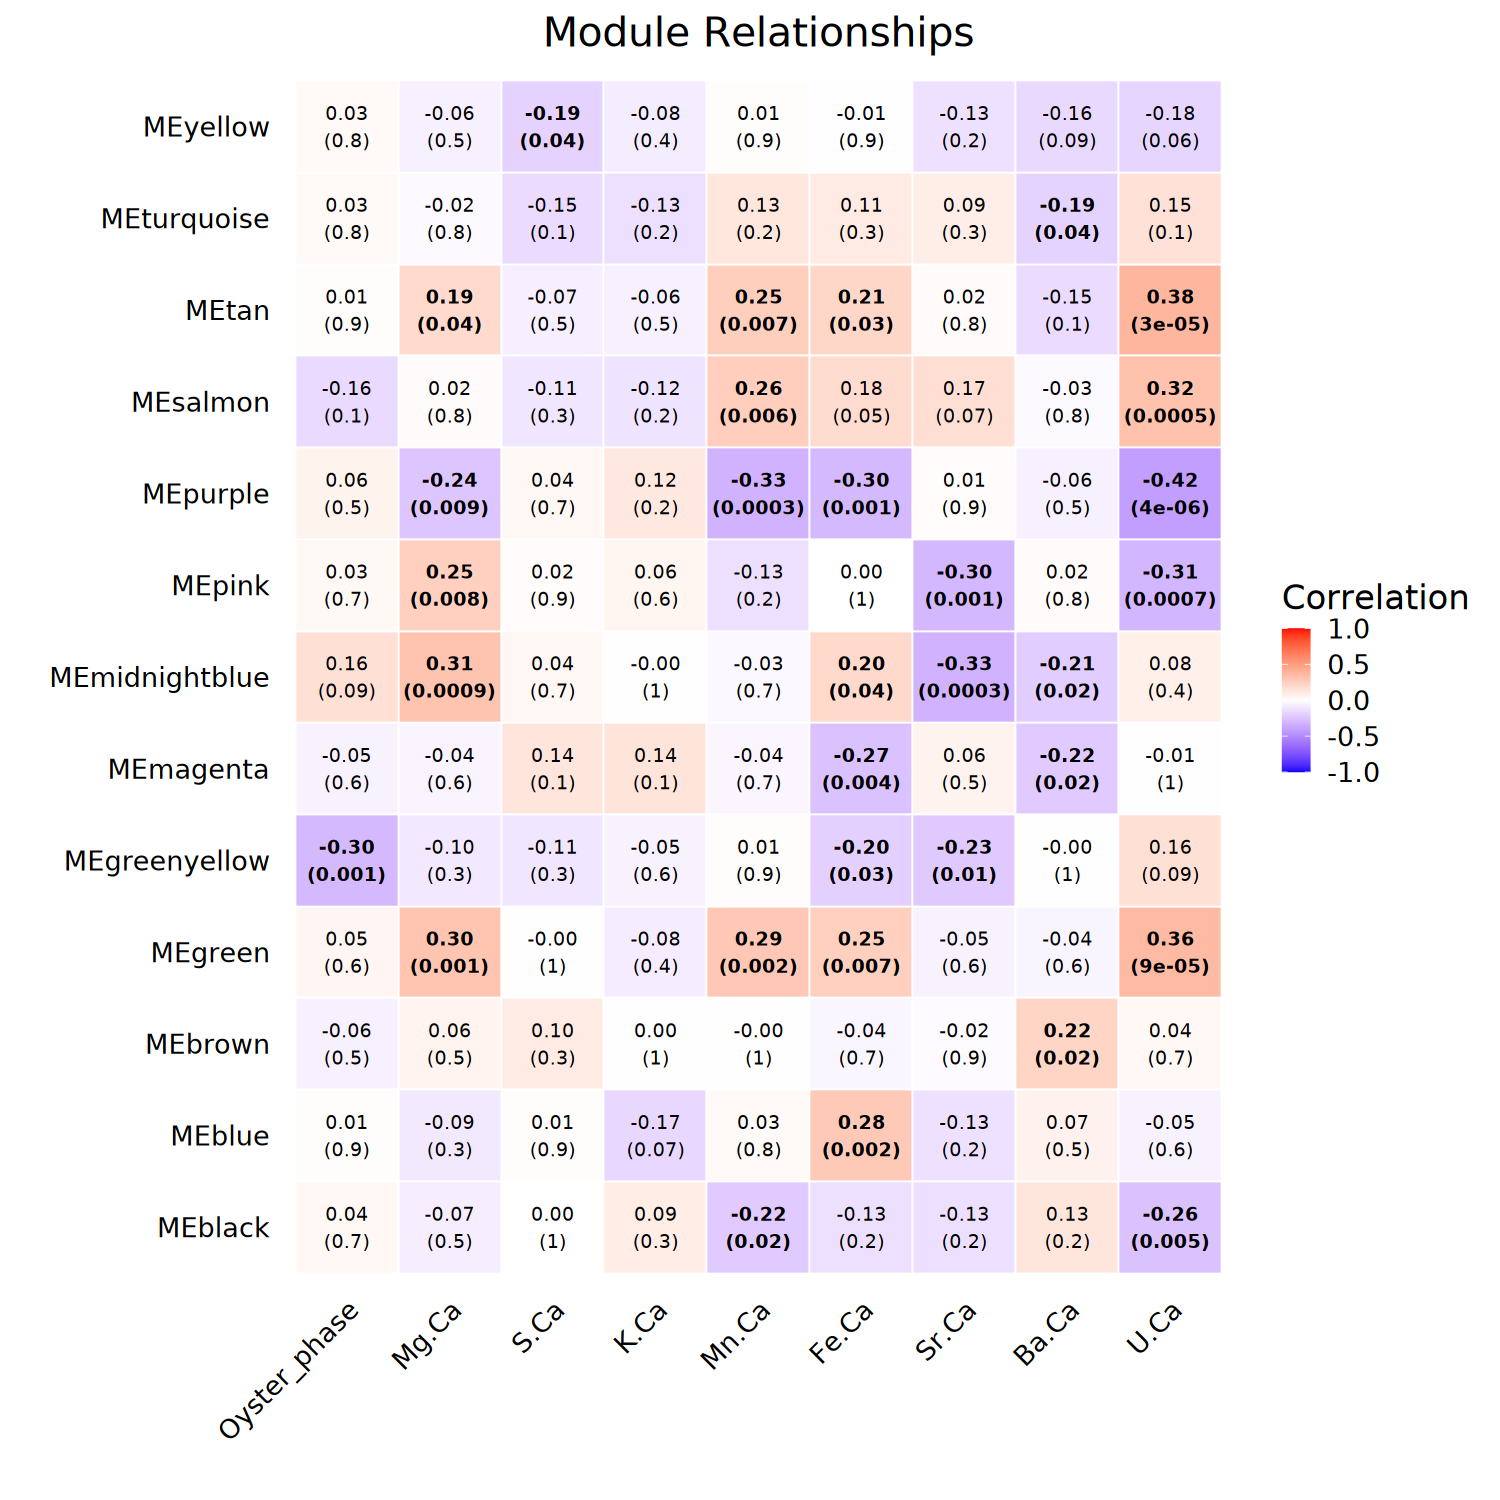

In [151]:
options(repr.plot.width = 12.5, repr.plot.height = 12.5)

module.df <- module.df %>%
  mutate(
    elemental_abundance = factor(
      elemental_abundance,
      levels = c("Oyster_phase", setdiff(unique(elemental_abundance), "Oyster_phase"))
    )
  )

#

heatmap1 <- ggplot(module.df, aes(x = elemental_abundance, y = module, fill = Cor)) +
  geom_tile(color = "white") +
  
  # text annotations
  geom_text(
    aes(
      label = label,
      fontface = ifelse(sig, "bold", "plain")
    ),
    size = 4
  ) +
  
  scale_fill_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    limits = c(-1, 1)
  ) +

  theme_minimal(base_size = 20) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1, color = 'black'),
      axis.text.y = element_text(color = 'black'),
    panel.grid = element_blank(),
      plot.title = element_text(hjust = .5),
      strip.text = element_text(color = 'black')
  ) +
  
  labs(
    title = "Module Relationships",
    x = "",
    y = "",
    fill = "Correlation"
  )

heatmap1

woah! lots of correlated modules with changes in relative elemental abundance and only one module that is correlated with the phase of the oyster (reminder that this is a subset of the samples used in the heatmap above)

All of theses elemental abundances are relative to calcium, hence the .Ca

for my reference:
- Ba = barium
- Fe = iron
- K = potassium
- Mg = magnesium
- Mn = manganese
- Na = sodium
- S = sulfur
- Sr = strontium
- U = uranium